<a href="https://colab.research.google.com/github/pavllychka/mll2/blob/main/mll4.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Лабораторна робота № 4
## Дослідження дерев рішень та ансамблевих методів у задачі багатокласової класифікації за наявності пропущених значень

**Мета роботи:** дослідити та порівняти три алгоритми класифікації — дерево рішень (`Decision Tree`), випадковий ліс (`Random Forest`) та градієнтний бустинг (`XGBoost`) — на реальному датасеті **Annealing**, що містить пропущені значення. Основну увагу приділено:
- впливу способу обробки пропусків на якість класифікації;
- коректному (без витоку даних) підбору гіперпараметрів за допомогою `Optuna`;
- неупередженому оцінюванню моделей (вкладена крос-валідація) та статистичному порівнянню результатів за скоригованим $t$-тестом Наде–Бенжіо;
- інтерпретації моделей і розбіжностей між їхніми прогнозами (`MDI`, `Permutation Importance`, `SHAP`).

In [1]:

!pip install -q "scikit-learn>=1.4" "xgboost>=2.0" "optuna>=3.0" "shap>=0.44" pandas matplotlib seaborn scipy

import sys
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from IPython.display import display, Markdown

import sklearn
import xgboost
import optuna
import shap

from sklearn.datasets import fetch_openml
from sklearn.model_selection import (
    train_test_split,
    StratifiedKFold,
    RepeatedStratifiedKFold,
    cross_validate,
    cross_val_score,
    cross_val_predict
)
from sklearn.preprocessing import LabelEncoder, OneHotEncoder
from sklearn.impute import SimpleImputer, MissingIndicator
from sklearn.compose import ColumnTransformer, make_column_selector
from sklearn.pipeline import Pipeline
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    balanced_accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)
from sklearn.inspection import permutation_importance

optuna.logging.set_verbosity(optuna.logging.WARNING)
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams['figure.dpi'] = 110


N = 1
SEED = 42 + N
np.random.seed(SEED)

# Фіксація версій бібліотек у файлі requirements.txt
!pip freeze > requirements.txt

print(f"Номер студента N = {N} | Константа випадковості SEED = {SEED}")
print(f"Python:       {sys.version.split()[0]}")
print(f"scikit-learn: {sklearn.__version__}")
print(f"xgboost:      {xgboost.__version__}")
print(f"optuna:       {optuna.__version__}")
print(f"shap:         {shap.__version__}")
print(f"pandas:       {pd.__version__}")
print("Файл requirements.txt успішно збережено в робочій директорії.")

Номер студента N = 1 | Константа випадковості SEED = 43
Python:       3.13.18
scikit-learn: 1.6.1
xgboost:      3.4.1
optuna:       5.1.0
shap:         0.54.1
pandas:       2.2.3
Файл requirements.txt успішно збережено в робочій директорії.


In [2]:


import urllib.parse
from matplotlib.patches import Patch, Rectangle
from matplotlib.lines import Line2D
from matplotlib.colors import PowerNorm
from matplotlib.ticker import PercentFormatter


from optuna.visualization.matplotlib import plot_optimization_history, plot_param_importances

CLASS_COLORS = {'1': '#c44e52', '2': '#dd8452', '3': '#4c72b0', '5': '#55a868', 'U': '#8172b3'}
MODEL_COLORS = {'DT': '#e9a23b', 'RF': '#2a9d8f', 'XGB': '#6a4c93'}
KIND_COLORS  = {'num': '#4c72b0', 'cat': '#a7b0bb', 'miss': '#c44e52'}
KIND_LABELS  = {'num': 'числова ознака', 'cat': 'категоріальна (one-hot)', 'miss': 'індикатор пропуску'}

def apply_theme():
    sns.set_theme(style='whitegrid', context='notebook')
    plt.rcParams.update({
        'figure.dpi': 110, 'savefig.dpi': 200, 'figure.facecolor': 'white', 'axes.facecolor': 'white',
        'axes.spines.top': False, 'axes.spines.right': False,
        'axes.titleweight': 'bold', 'axes.titlesize': 12, 'axes.labelsize': 10.5,
        'grid.alpha': 0.45, 'legend.frameon': False,
    })
apply_theme()


def feature_kind(name):
    if name.startswith('miss__'): return 'miss'
    return 'num' if name.startswith('num__') else 'cat'

def raw_feature(name):
    """Назва ПОЧАТКОВОЇ ознаки (як у X.columns) за назвою ознаки після обробки."""
    p_miss = 'miss__missingindicator_'
    if name.startswith(p_miss): return name[len(p_miss):]
    if name.startswith('miss__'): return name[len('miss__'):]
    if name.startswith('num__'): return name[len('num__'):]
    body = name[len('cat__'):] if name.startswith('cat__') else name
    for c in sorted(X.select_dtypes(exclude='number').columns, key=len, reverse=True):
        if body.startswith(c + '_'): return c
    return body

def pretty_feature(name):
    """Читабельна підпис ознаки для графіків."""
    kind, col = feature_kind(name), raw_feature(name)
    if kind == 'miss': return urllib.parse.unquote(col) + ' · пропуск'
    if kind == 'num':  return urllib.parse.unquote(col)
    cat = name[len('cat__'):][len(col) + 1:]
    return f"{urllib.parse.unquote(col)} = {urllib.parse.unquote(cat)}"

## 3.1. Первинний аналіз даних
1. Завантажуємо датасет **Annealing** (`name='anneal', version=1`) з OpenML (898 спостережень, 38 ознак).
2. Приводимо категоріальні ознаки до типу `object` (оскільки `fetch_openml` повертає тип `category`, а в окремих версіях датасету невизначені значення можуть позначатися символом `'?'`).
3. Визначаємо кількість спостережень, ознак та їхні типи.
4. Обчислюємо частку пропусків для кожної ознаки та видаляємо повністю порожні або константні ознаки з обґрунтуванням.

In [3]:

data = fetch_openml(name='anneal', version=1, as_frame=True, parser='auto')
X_raw, y_raw = data.data.copy(), data.target.copy()


for col in X_raw.columns:
    if isinstance(X_raw[col].dtype, pd.CategoricalDtype) or X_raw[col].dtype == object:
        X_raw[col] = X_raw[col].astype(object)
        X_raw[col] = X_raw[col].replace({'?': np.nan, b'?': np.nan})


n_samples, n_features = X_raw.shape
num_cols_raw = X_raw.select_dtypes(include='number').columns.tolist()
cat_cols_raw = X_raw.select_dtypes(exclude='number').columns.tolist()

print(f"Використана версія датасету: OpenML 'anneal' version=1")
print(f"Кількість спостережень: {n_samples}")
print(f"Початкова кількість ознак: {n_features}")
print(f"  - Числових ознак ({len(num_cols_raw)}): {num_cols_raw}")
print(f"  - Категоріальних/бінарних ознак типу object ({len(cat_cols_raw)}): {cat_cols_raw}")

Використана версія датасету: OpenML 'anneal' version=1
Кількість спостережень: 898
Початкова кількість ознак: 38
  - Числових ознак (12): ['carbon', 'hardness', 'strength', 'm', 'marvi', 'corr', 'jurofm', 's', 'p', 'thick', 'width', 'len']
  - Категоріальних/бінарних ознак типу object (26): ['family', 'product-type', 'steel', 'temper_rolling', 'condition', 'formability', 'non-ageing', 'surface-finish', 'surface-quality', 'enamelability', 'bc', 'bf', 'bt', 'bw%2Fme', 'bl', 'chrom', 'phos', 'cbond', 'exptl', 'ferro', 'blue%2Fbright%2Fvarn%2Fclean', 'lustre', 'shape', 'oil', 'bore', 'packing']


### Аналіз пропусків та видалення неінформативних (порожніх і константних) ознак

,Тип,Кількість пропусків,Частка пропусків (%),К-сть унікальних (без NaN),К-сть унікальних (з NaN)
marvi,float64,898,100.00,0,1
s,float64,898,100.00,0,1
p,float64,898,100.00,0,1
corr,float64,898,100.00,0,1
jurofm,float64,898,100.00,0,1
m,float64,898,100.00,0,1
bc,object,897,99.89,1,2
exptl,object,896,99.78,1,2
blue%2Fbright%2Fvarn%2Fclean,object,892,99.33,3,4
phos,object,891,99.22,1,2


Повністю порожні ознаки (100% пропусків): ['marvi', 's', 'p', 'corr', 'jurofm', 'm']
Константні ознаки без пропусків (1 унікальне значення у всіх 898 рядках): ['product-type']
Видаляємо ознаки (7 шт.): ['corr', 'jurofm', 'm', 'marvi', 'p', 'product-type', 's']
Розмірність матриці ознак X після очищення: (898, 31)


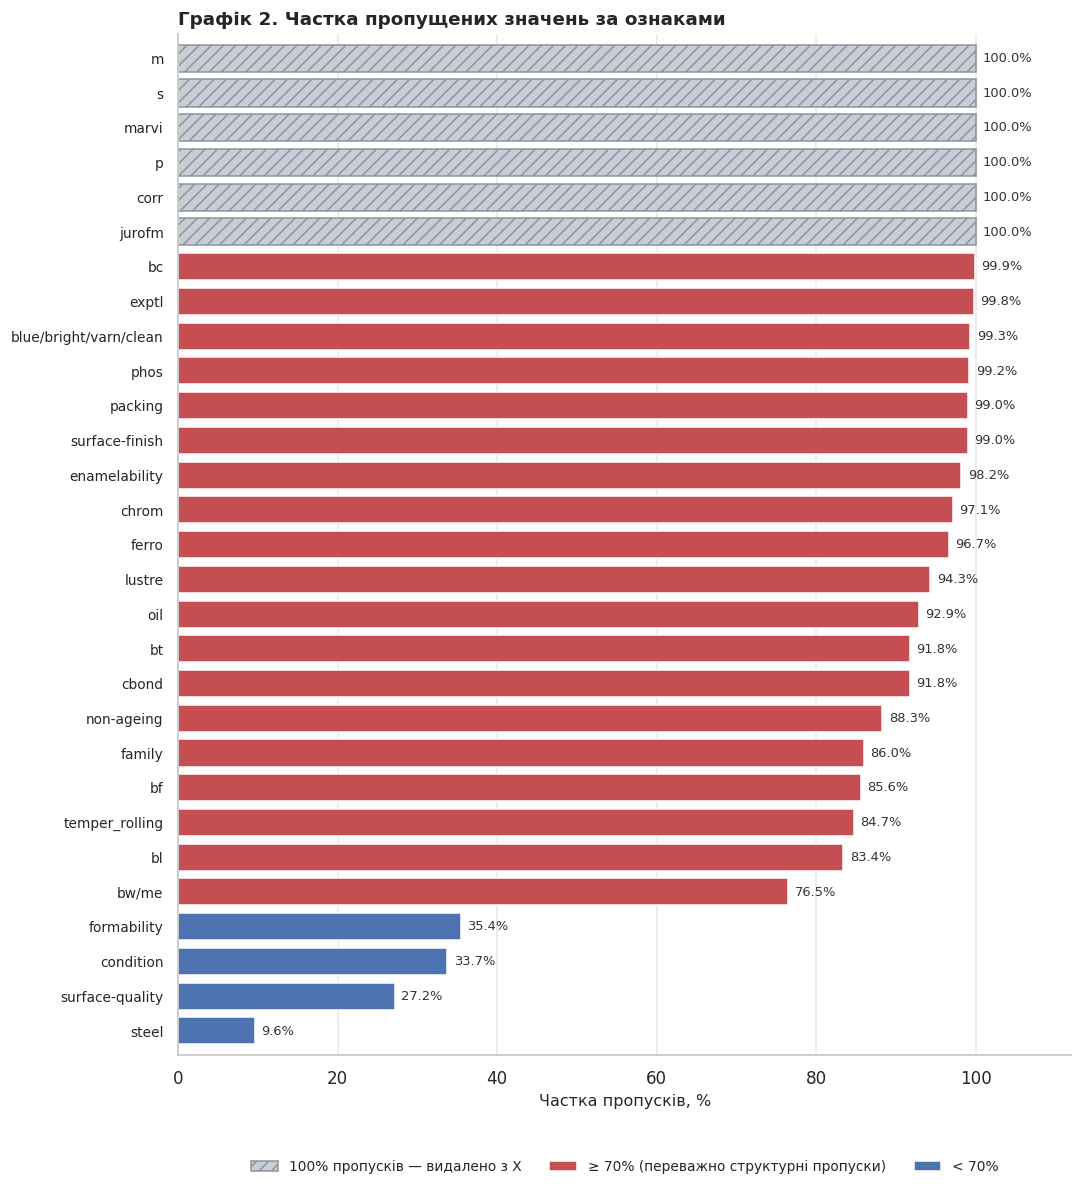

In [4]:


missing_stats = pd.DataFrame({
    'Тип': X_raw.dtypes.astype(str),
    'Кількість пропусків': X_raw.isna().sum(),
    'Частка пропусків (%)': (X_raw.isna().mean() * 100).round(2),
    'К-сть унікальних (без NaN)': X_raw.nunique(dropna=True),
    'К-сть унікальних (з NaN)': X_raw.nunique(dropna=False)
}).sort_values(by='Частка пропусків (%)', ascending=False)

display(missing_stats)


empty_cols = missing_stats[missing_stats['Кількість пропусків'] == n_samples].index.tolist()
constant_no_nan_cols = missing_stats[
    (missing_stats['К-сть унікальних (без NaN)'] <= 1) & (missing_stats['Кількість пропусків'] == 0)
].index.tolist()


cols_to_drop = sorted(list(set(empty_cols + constant_no_nan_cols)))

print(f"Повністю порожні ознаки (100% пропусків): {empty_cols}")
print(f"Константні ознаки без пропусків (1 унікальне значення у всіх {n_samples} рядках): {constant_no_nan_cols}")
print(f"Видаляємо ознаки ({len(cols_to_drop)} шт.): {cols_to_drop}")

X = X_raw.drop(columns=cols_to_drop).copy()
print(f"Розмірність матриці ознак X після очищення: {X.shape}")

# ---------------- Графік 2: частка пропусків за ознаками ----------------
apply_theme()
miss_plot = missing_stats[missing_stats['Частка пропусків (%)'] > 0].sort_values('Частка пропусків (%)', ascending=True)
shares = miss_plot['Частка пропусків (%)'].values
groups = ['drop' if c in cols_to_drop else ('struct' if s >= 70 else 'moderate')
          for c, s in zip(miss_plot.index, shares)]
grp_color = {'drop': '#c9ced6', 'struct': '#c44e52', 'moderate': '#4c72b0'}

fig, ax = plt.subplots(figsize=(10, 0.30 * len(miss_plot) + 2.2))
bars = ax.barh(range(len(miss_plot)), shares, color=[grp_color[g] for g in groups], edgecolor='white', height=0.78)
for b, g in zip(bars, groups):
    if g == 'drop':
        b.set_hatch('///'); b.set_edgecolor('#8d949e')
for i, v in enumerate(shares):
    ax.text(v + 0.8, i, f'{v:.1f}%', va='center', fontsize=8.5, color='#333')
ax.set_yticks(range(len(miss_plot)), [urllib.parse.unquote(c) for c in miss_plot.index], fontsize=9)
ax.set_xlim(0, 112); ax.set_ylim(-0.7, len(miss_plot) - 0.3)
ax.set_xlabel('Частка пропусків, %'); ax.grid(axis='y', visible=False)
ax.set_title('Графік 2. Частка пропущених значень за ознаками', loc='left')
ax.legend(handles=[Patch(facecolor=grp_color['drop'], hatch='///', edgecolor='#8d949e', label='100% пропусків — видалено з X'),
                   Patch(facecolor=grp_color['struct'], label='≥ 70% (переважно структурні пропуски)'),
                   Patch(facecolor=grp_color['moderate'], label='< 70%')],
          loc='upper center', bbox_to_anchor=(0.5, -0.09), ncol=3, fontsize=9)
plt.tight_layout(); plt.show()

**Коментар до аналізу пропусків та очищення ознак:**
- У датасеті **Annealing** значна частина ознак має дуже високу частку пропусків (понад 70–99%). Згідно з документацією `anneal.names`, у вихідних даних символ `'-'` (перетворений у ARFF/OpenML на пропуск `NaN`) часто позначає **структурну відсутність властивості** або негативне значення бінарного прапорця (наприклад, для ознак типу `bc`, `bf`, `bt`, `bl`, `chrom`, `phos`, `cbond` наявні лише значення `'Y'`/`'C'`/`'P'` та пропуски).
- Ознаки, що є **повністю порожніми** (100% пропусків) або **строго константними** (мають лише 1 унікальне значення й жодного пропуску, тобто нульову дисперсію), не несуть жодної роздільної здатності для дерев рішень і можуть викликати помилки під час медіанної імпутації, тому їх обґрунтовано видалено. Натомість ознаки з пропусками та одним непропущеним значенням залишено, оскільки для варіанту B індикатор пропуску (`MissingIndicator`) перетворює їх на повноцінні бінарні ознаки.

### Розподіл цільової змінної та перевірка рідкісних класів

,Кількість спостережень,Частка (%)
class,,
1,8,0.89
2,99,11.02
3,684,76.17
5,67,7.46
U,40,4.45


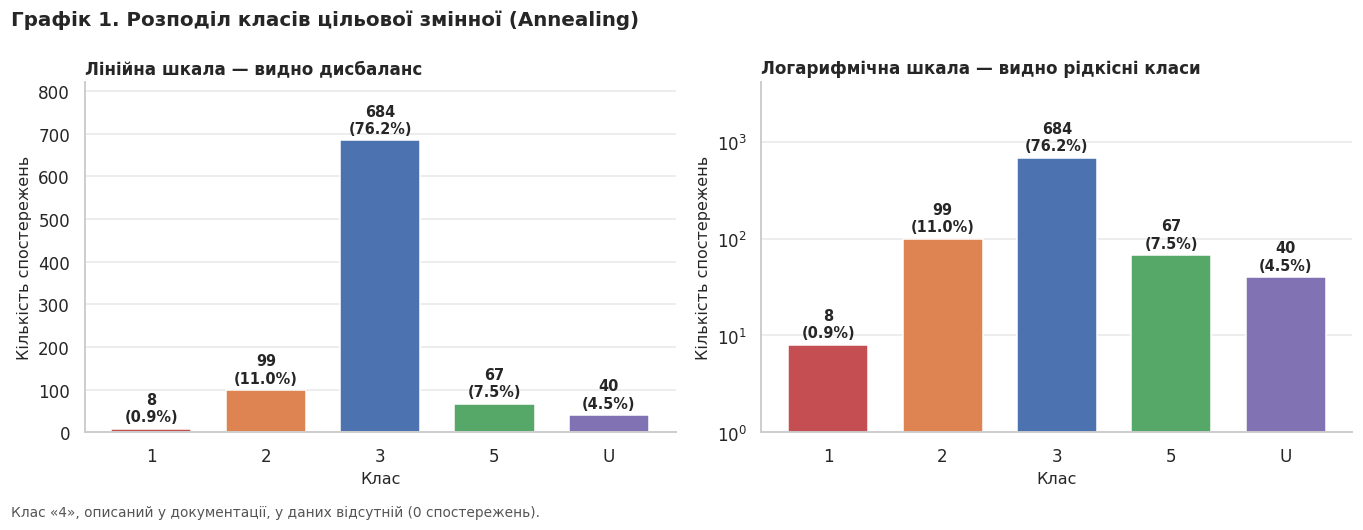

In [5]:

# 4. Аналіз розподілу цільової змінної
class_counts = y_raw.value_counts().sort_index()
class_props = (y_raw.value_counts(normalize=True).sort_index() * 100).round(2)
target_df = pd.DataFrame({
    'Кількість спостережень': class_counts,
    'Частка (%)': class_props
})
display(target_df)

# ---------------- Графік 1: розподіл класів (лінійна + логарифмічна шкала) ----------------
apply_theme()
labels = target_df.index.astype(str).tolist()
counts = target_df['Кількість спостережень'].values
props = target_df['Частка (%)'].values
colors = [CLASS_COLORS.get(l, '#999999') for l in labels]

fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.6))
for ax, log in zip(axes, (False, True)):
    bars = ax.bar(labels, counts, color=colors, edgecolor='white', width=0.7)
    for b, n, p in zip(bars, counts, props):
        ax.annotate(f'{n}\n({p:.1f}%)', (b.get_x() + b.get_width() / 2, n), xytext=(0, 3),
                    textcoords='offset points', ha='center', va='bottom', fontsize=9.5, fontweight='bold')
    if log:
        ax.set_yscale('log'); ax.set_ylim(1, counts.max() * 6)
        ax.set_title('Логарифмічна шкала — видно рідкісні класи', loc='left', fontsize=11)
    else:
        ax.set_ylim(0, counts.max() * 1.2)
        ax.set_title('Лінійна шкала — видно дисбаланс', loc='left', fontsize=11)
    ax.set_xlabel('Клас'); ax.set_ylabel('Кількість спостережень'); ax.grid(axis='x', visible=False)
fig.suptitle('Графік 1. Розподіл класів цільової змінної (Annealing)', fontsize=13, fontweight='bold', x=0.01, ha='left')
fig.text(0.01, -0.02, 'Клас «4», описаний у документації, у даних відсутній (0 спостережень).', fontsize=9, color='#555')
plt.tight_layout(); plt.show()

**Коментар щодо розподілу цільової змінної та рідкісних класів:**
- Цільова змінна містить **5 класів** (`1`, `2`, `3`, `5`, `U`), а клас `4`, згаданий у документації UCI, у вибірці повністю відсутній (0 спостережень).
- Спостерігається **сильний дисбаланс класів**: клас `3` домінує (684 спостереження, ~76.17%), тоді як найменший клас `1` містить лише **8 спостережень** (~0.89%).
- **Обґрунтування рішення щодо рідкісного класу `1` (залишити всі наявні 5 класів):**
  При стратифікованому поділі 80/20 у тренувальну вибірку `X_train` потрапляє $8 \times 0.8 = 6$ об'єктів класу `1`, а в тестову `X_test` — $2$ об'єкти.
  - На рівні **зовнішньої 5-блочної крос-валідації** (`n_splits=5`) у кожну тренувальну частину блоку потрапляє $4$ або $5$ об'єктів класу `1`, а у валідаційну — щонайменше $1$ об'єкт.
  - На рівні **внутрішньої 3-блочної крос-валідації Optuna** (`n_splits=3`) $4–5$ об'єктів класу `1` гарантовано розподіляються так, що в кожному внутрішньому блоці є принаймні $1$ представник класу `1`.
  Отже, залишаючи клас `1`, ми зберігаємо оригінальну постановку задачі багатокласової класифікації без помилок `StratifiedKFold` та `XGBoost`, але через малу кількість об'єктів (2 у тесті) метрика `macro F1` буде чутливою до кожної помилки на класі `1`.

### Аналіз механізму виникнення пропусків ($\chi^2$-тест незалежності) та кодування цільової змінної


Таблиця спряженості «пропуск / не пропуск» × клас для ознаки 'bc':


class,1,2,3,5,U
bc,,,,,
Не пропуск,0,0,1,0,0
Пропуск,8,99,683,67,40



Таблиця спряженості «пропуск / не пропуск» × клас для ознаки 'exptl':


class,1,2,3,5,U
exptl,,,,,
Не пропуск,2,0,0,0,0
Пропуск,6,99,684,67,40



Таблиця спряженості «пропуск / не пропуск» × клас для ознаки 'blue/bright/varn/clean':


class,1,2,3,5,U
blue/bright/varn/clean,,,,,
Не пропуск,1,4,1,0,0
Пропуск,7,95,683,67,40


... (2 outputs left out)


Таблиця спряженості «пропуск / не пропуск» × клас для ознаки 'surface-finish':


class,1,2,3,5,U
surface-finish,,,,,
Не пропуск,0,9,0,0,0
Пропуск,8,90,684,67,40



Підсумкова таблиця перевірки незалежності пропусків від класу (Monte-Carlo χ², 9 тестів, поправка Бонферроні):


,Ознака,Група,Частка пропусків (%),К-сть значень (не NaN),χ²,df,Мін. очікувана частота,p (асимпт. χ²),p (Monte-Carlo),p (Бонферроні),Висновок (α = 0.05)
0,bc,Топ-5 за часткою пропусків,99.89,1,0.313,4,0.009,0.989,1.0000,1.0000,Тест малопотужний (замало спостережень)
1,exptl,Топ-5 за часткою пропусків,99.78,2,222.997,4,0.018,4.25e-47,0.0001,0.0009,Залежить від класу (не MCAR)
2,blue/bright/varn/clean,Топ-5 за часткою пропусків,99.33,6,37.365,4,0.053,1.51e-07,0.0021,0.0189,Залежить від класу (не MCAR)
3,phos,Топ-5 за часткою пропусків,99.22,7,87.503,4,0.062,4.46e-18,0.0001,0.0009,Залежить від класу (не MCAR)
4,surface-finish,Топ-5 за часткою пропусків,99.00,9,73.372,4,0.080,4.4e-15,0.0001,0.0009,Залежить від класу (не MCAR)
5,formability,Помірна частка пропусків,35.41,580,136.162,4,2.833,1.87e-28,0.0001,0.0009,Залежить від класу (не MCAR)
6,condition,Помірна частка пропусків,33.74,595,151.047,4,2.699,1.21e-31,0.0001,0.0009,Залежить від класу (не MCAR)
7,surface-quality,Помірна частка пропусків,27.17,654,495.580,4,2.174,6.05e-106,0.0001,0.0009,Залежить від класу (не MCAR)
8,steel,Помірна частка пропусків,9.58,812,33.346,4,0.766,1.01e-06,0.0002,0.0018,Залежить від класу (не MCAR)


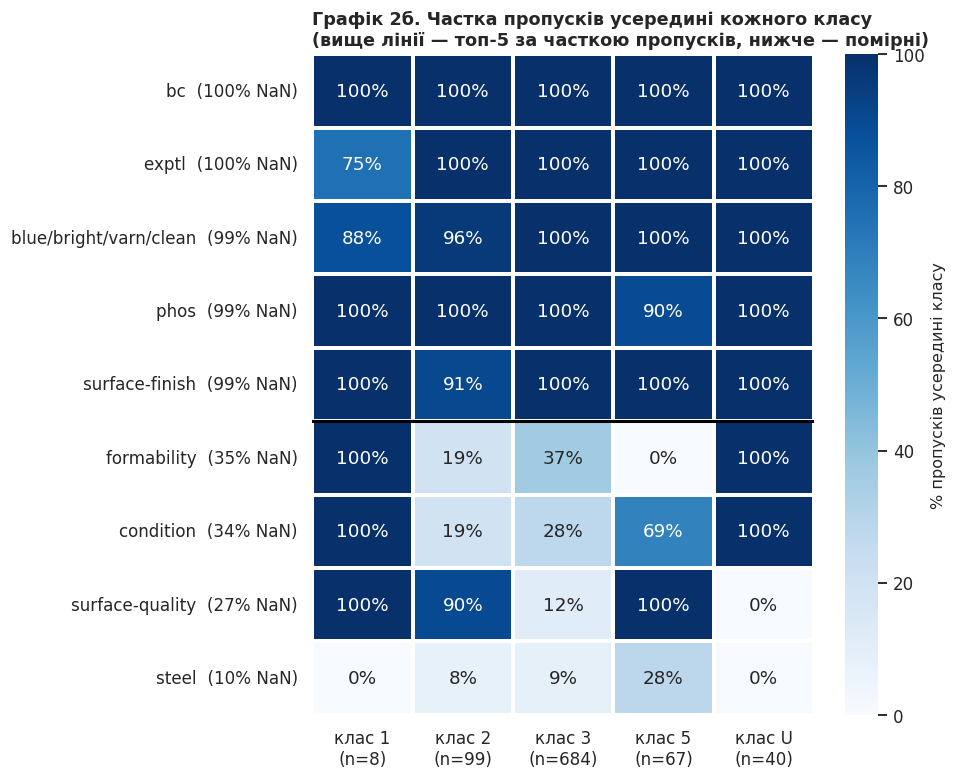


Кодування класів LabelEncoder: {'1': 0, '2': 1, '3': 2, '5': 3, 'U': 4}


In [6]:

# 5. Аналіз механізму пропусків
# (а) Ознаки: 5 з найбільшою часткою пропусків (як у методичці) + 4 з помірною часткою (5–70%),
#     де кількості спостережень достатньо для коректного тесту.
miss_share = X.isna().mean()
top_missing_features = miss_share.loc[lambda s: (s > 0) & (s < 1.0)].sort_values(ascending=False).head(5).index.tolist()
moderate_features = miss_share.loc[lambda s: (s > 0.05) & (s < 0.70)].sort_values(ascending=False).head(4).index.tolist()
test_features = [(f, 'Топ-5 за часткою пропусків') for f in top_missing_features] + \
                [(f, 'Помірна частка пропусків') for f in moderate_features if f not in top_missing_features]

y_str = y_raw.astype(str).reset_index(drop=True)
class_order = sorted(y_str.unique())
K = len(class_order)
y_codes = pd.Categorical(y_str, categories=class_order).codes.astype(int)

# (б) Для ознак, у яких майже всі значення пропущені, очікувані частоти в таблиці «пропуск × клас» << 5,
#     тому асимптотичний χ² некоректний (методичка вимагає точний критерій для малих частот).
#     Використовуємо Monte-Carlo перестановочний χ²-тест — точний аналог критерію Фішера для таблиці 2×K.
def chi2_from_table(tab):
    tab = tab.astype(float)
    exp = tab.sum(1, keepdims=True) * tab.sum(0, keepdims=True) / tab.sum()
    mask = exp > 0
    return float((((tab - exp) ** 2)[mask] / exp[mask]).sum())

def mc_chi2_pvalue(miss_flag, y_codes, K, n_perm=10000, seed=SEED):
    rng = np.random.default_rng(seed)
    m = miss_flag.astype(int)
    obs = chi2_from_table(np.bincount(m * K + y_codes, minlength=2 * K).reshape(2, K))
    hits = 0
    for _ in range(n_perm):
        perm = rng.permutation(y_codes)
        hits += chi2_from_table(np.bincount(m * K + perm, minlength=2 * K).reshape(2, K)) >= obs - 1e-9
    return obs, (hits + 1) / (n_perm + 1)

chi2_results = []
for feat, grp in test_features:
    miss_flag = X[feat].isna().values
    ct = pd.crosstab(pd.Series(np.where(miss_flag, 'Пропуск', 'Не пропуск'), name=urllib.parse.unquote(feat)),
                     pd.Series(y_str.values, name='class'))
    chi2_stat, p_asym, dof, expected = stats.chi2_contingency(ct)
    _, p_mc = mc_chi2_pvalue(miss_flag, y_codes, K)
    p_bonf = min(1.0, p_mc * len(test_features))
    n_obs = int((~miss_flag).sum())
    if p_bonf < 0.05:
        verdict = 'Залежить від класу (не MCAR)'
    elif n_obs < 10:
        verdict = 'Тест малопотужний (замало спостережень)'
    else:
        verdict = 'Немає доказів залежності (сумісне з MCAR)'
    chi2_results.append({
        'Ознака': urllib.parse.unquote(feat), 'Група': grp,
        'Частка пропусків (%)': round(miss_share[feat] * 100, 2), 'К-сть значень (не NaN)': n_obs,
        'χ²': round(chi2_stat, 3), 'df': dof, 'Мін. очікувана частота': round(float(expected.min()), 3),
        'p (асимпт. χ²)': f"{p_asym:.3g}", 'p (Monte-Carlo)': f"{p_mc:.4f}", 'p (Бонферроні)': f"{p_bonf:.4f}",
        'Висновок (α = 0.05)': verdict
    })
    if feat in top_missing_features:
        print(f"\nТаблиця спряженості «пропуск / не пропуск» × клас для ознаки '{urllib.parse.unquote(feat)}':")
        display(ct)

chi2_df = pd.DataFrame(chi2_results)
print("\nПідсумкова таблиця перевірки незалежності пропусків від класу "
      f"(Monte-Carlo χ², {len(test_features)} тестів, поправка Бонферроні):")
display(chi2_df)

# ---------------- Графік 2б: частка пропусків усередині кожного класу ----------------
apply_theme()
by_class = pd.DataFrame({f: X[f].isna().groupby(y_str.values).mean() * 100 for f, _ in test_features}).T[class_order]
cls_n = y_str.value_counts()
row_labels = [f"{urllib.parse.unquote(f)}  ({miss_share[f] * 100:.0f}% NaN)" for f, _ in test_features]
col_labels = [f'клас {c}\n(n={cls_n[c]})' for c in class_order]
annot = np.array([[f'{v:.0f}%' for v in row] for row in by_class.values])

fig, ax = plt.subplots(figsize=(8.8, 0.55 * len(test_features) + 2.3))
sns.heatmap(by_class.values, annot=annot, fmt='', cmap='Blues', vmin=0, vmax=100, linewidths=1.5, linecolor='white',
            xticklabels=col_labels, yticklabels=row_labels, cbar_kws={'label': '% пропусків усередині класу'}, ax=ax)
if 0 < len(top_missing_features) < len(test_features):
    ax.axhline(len(top_missing_features), color='black', lw=2)
ax.set_title('Графік 2б. Частка пропусків усередині кожного класу\n(вище лінії — топ-5 за часткою пропусків, нижче — помірні)', loc='left', fontsize=11.5)
ax.tick_params(axis='y', rotation=0); ax.set_xlabel(''); ax.set_ylabel('')
plt.tight_layout(); plt.show()

# 6. Кодування цільової змінної цілими числами 0, ..., K-1 за допомогою LabelEncoder
le = LabelEncoder()
y_enc = le.fit_transform(y_raw)
class_names = [str(c) for c in le.classes_]
print(f"\nКодування класів LabelEncoder: {dict(zip(class_names, range(len(class_names))))}")


**Висновок щодо механізму пропусків (MCAR / MAR / MNAR):**
- Для ознак із **помірною часткою пропусків** (5–70%) в таблиці спряженості достатньо спостережень, тому тест коректний. Якщо `p (Бонферроні) < 0.05`, гіпотезу про незалежність пропуску від класу відхиляємо: пропуски **не є MCAR**, а факт пропуску несе інформацію про клас (Графік 2б наочно показує, у яких класах ознака «зникає» майже завжди або майже ніколи).
- Для ознак, що майже повністю порожні (99%+), у таблиці лишається 1–10 значень, очікувані частоти значно менші за 5 — **асимптотичний χ² тут некоректний** (методичка вимагає точний критерій для малих частот). Тому застосовано Monte-Carlo перестановочний χ²-тест, а в таблиці наведено «Мін. очікувана частоту» як індикатор валідності. Незначущий результат для такої ознаки (наприклад, лише 1 непропущене значення) означає **малу потужність тесту**, а не доказ MCAR.
- Загалом структура пропусків має **структурний характер** (операція чи вимірювання застосовна лише до певних марок/класів сталі), тобто відповідає MAR/MNAR; однозначно відрізнити MAR від MNAR лише за наявними даними неможливо. Це теоретично обґрунтовує Варіант B (індикатори пропусків).

## 3.2. Поділ даних і пайплайн обробки та 3.3. Базові моделі
Виконуємо стратифікований поділ на тренувальну (80%) і тестову (20%) вибірки, перевіряємо мінімальну кількість об'єктів кожного класу та будуємо два варіанти обробки:
- **Варіант A (базова імпутація):** числові — медіана, категоріальні — мода + One-Hot кодування.
- **Варіант B (імпутація з індикаторами пропусків):** Варіант A + бінарні індикатори `MissingIndicator(features='missing-only')`.

Розмір тренувальної вибірки X_train: (718, 31)
Розмір тестової вибірки X_test:      (180, 31)
Розподіл класів у y_train: {'1': np.int64(6), '2': np.int64(79), '3': np.int64(547), '5': np.int64(54), 'U': np.int64(32)}
Розподіл класів у y_test:  {'1': np.int64(2), '2': np.int64(20), '3': np.int64(137), '5': np.int64(13), 'U': np.int64(8)}


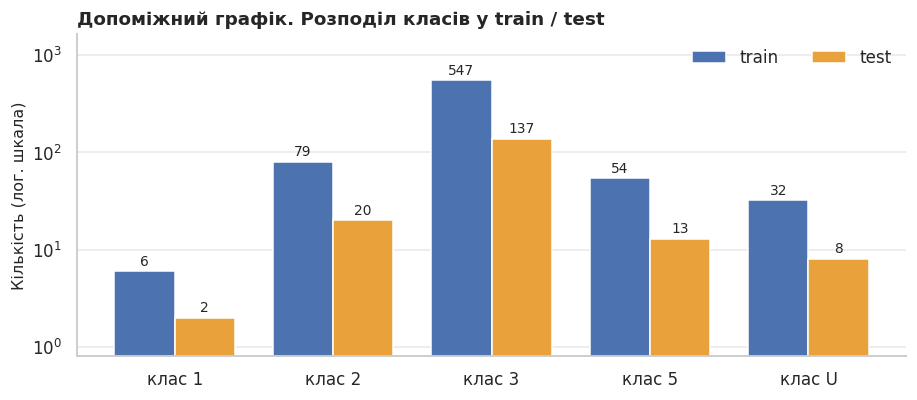

In [7]:
# 3.2. Стратифікований поділ даних
X_train, X_test, y_train, y_test = train_test_split(
    X, y_enc, test_size=0.2, stratify=y_enc, random_state=SEED
)

print(f"Розмір тренувальної вибірки X_train: {X_train.shape}")
print(f"Розмір тестової вибірки X_test:      {X_test.shape}")
print("Розподіл класів у y_train:", dict(zip(class_names, np.bincount(y_train))))
print("Розподіл класів у y_test: ", dict(zip(class_names, np.bincount(y_test))))

# Побудова препроцесора та пайплайну згідно з методичкою
def build_preprocessor(with_indicators: bool) -> ColumnTransformer:
    transformers = [
        ('num', SimpleImputer(strategy='median'),
         make_column_selector(dtype_include='number')),
        ('cat', Pipeline([
            ('impute', SimpleImputer(strategy='most_frequent')),
            ('onehot', OneHotEncoder(handle_unknown='ignore', sparse_output=False)),
        ]), make_column_selector(dtype_exclude='number')),
    ]
    if with_indicators:
        transformers.append(
            ('miss', MissingIndicator(features='missing-only'),
             make_column_selector())
        )
    return ColumnTransformer(transformers)

def make_model(name, params=None):
    params = params or {}
    if name == 'DT':
        return DecisionTreeClassifier(random_state=SEED, **params)
    if name == 'RF':
        return RandomForestClassifier(random_state=SEED, n_jobs=-1, **params)
    return XGBClassifier(random_state=SEED, n_jobs=-1, eval_metric='mlogloss', **params)

def build_pipeline(name, with_indicators=True, params=None):
    return Pipeline([
        ('prep', build_preprocessor(with_indicators)),
        ('clf', make_model(name, params))
    ])

# Допоміжний графік: розподіл класів у train/test (пояснює чутливість Macro F1 до класу «1» у тесті)
apply_theme()
split_df = pd.DataFrame({'train': np.bincount(y_train), 'test': np.bincount(y_test)}, index=class_names)
fig, ax = plt.subplots(figsize=(8.5, 3.8))
xpos = np.arange(len(class_names)); w = 0.38
b1 = ax.bar(xpos - w / 2, split_df['train'], w, label='train', color='#4c72b0', edgecolor='white')
b2 = ax.bar(xpos + w / 2, split_df['test'], w, label='test', color='#e9a23b', edgecolor='white')
for bars in (b1, b2):
    ax.bar_label(bars, padding=2, fontsize=9)
ax.set_yscale('log'); ax.set_ylim(0.8, split_df.values.max() * 3)
ax.set_xticks(xpos, [f'клас {c}' for c in class_names])
ax.set_ylabel('Кількість (лог. шкала)'); ax.grid(axis='x', visible=False)
ax.set_title('Допоміжний графік. Розподіл класів у train / test', loc='left'); ax.legend(ncol=2)
plt.tight_layout(); plt.show()

### Оцінювання базових моделей повторною стратифікованою крос-валідацією (5 блоків × 3 повторення)

Таблиця 1. Результати крос-валідації (5 блоків × 3 повторення), Варіант A (базова імпутація), типові параметри:


,Модель,Accuracy,Macro F1 (основна),Balanced Accuracy
0,Decision Tree,0.9443 ± 0.0187,0.8984 ± 0.0746,0.9084 ± 0.0699
1,Random Forest,0.9549 ± 0.0196,0.9468 ± 0.0230,0.9485 ± 0.0241
2,XGBoost,0.9517 ± 0.0191,0.9131 ± 0.0720,0.9155 ± 0.0669



Таблиця 2. Результати крос-валідації (5 блоків × 3 повторення), Варіант B (з індикаторами пропусків), типові параметри:


,Модель,Accuracy,Macro F1 (основна),Balanced Accuracy
0,Decision Tree,0.9963 ± 0.0074,0.9931 ± 0.0110,0.9944 ± 0.0113
1,Random Forest,0.9977 ± 0.0043,0.9959 ± 0.0075,0.9994 ± 0.0011
2,XGBoost,0.9940 ± 0.0074,0.9623 ± 0.0725,0.9655 ± 0.0727


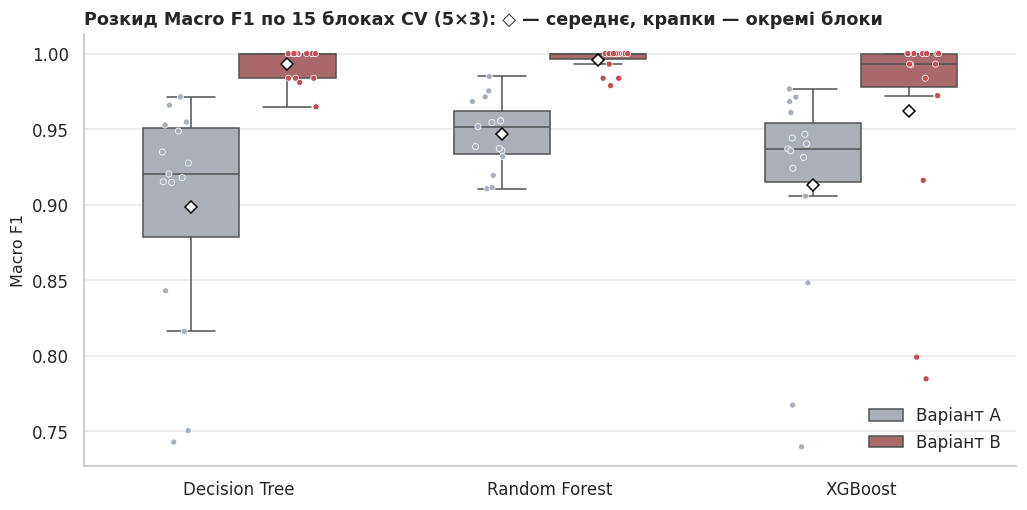

In [8]:
# 3.3. Оцінювання базових моделей на одному спільному об'єкті cv
scoring = {
    'acc': 'accuracy',
    'f1m': 'f1_macro',
    'bacc': 'balanced_accuracy'
}
cv = RepeatedStratifiedKFold(n_splits=5, n_repeats=3, random_state=SEED)

models_list = ['DT', 'RF', 'XGB']
model_labels = {'DT': 'Decision Tree', 'RF': 'Random Forest', 'XGB': 'XGBoost'}

cv_raw_scores = {'A': {}, 'B': {}}
rows_A, rows_B = [], []

for variant, with_ind, rows_list in [('A', False, rows_A), ('B', True, rows_B)]:
    for m in models_list:
        res = cross_validate(
            build_pipeline(m, with_indicators=with_ind),
            X_train, y_train, cv=cv, scoring=scoring, n_jobs=-1
        )
        cv_raw_scores[variant][m] = res
        rows_list.append({
            'Модель': model_labels[m],
            'Accuracy': f"{res['test_acc'].mean():.4f} ± {res['test_acc'].std(ddof=1):.4f}",
            'Macro F1 (основна)': f"{res['test_f1m'].mean():.4f} ± {res['test_f1m'].std(ddof=1):.4f}",
            'Balanced Accuracy': f"{res['test_bacc'].mean():.4f} ± {res['test_bacc'].std(ddof=1):.4f}",
            '_f1_mean': res['test_f1m'].mean()
        })

table1_df = pd.DataFrame(rows_A).drop(columns=['_f1_mean'])
table2_df = pd.DataFrame(rows_B).drop(columns=['_f1_mean'])

print("Таблиця 1. Результати крос-валідації (5 блоків × 3 повторення), Варіант A (базова імпутація), типові параметри:")
display(table1_df)

print("\nТаблиця 2. Результати крос-валідації (5 блоків × 3 повторення), Варіант B (з індикаторами пропусків), типові параметри:")
display(table2_df)

# Допоміжний графік: розкид Macro F1 по 15 блоках повторної CV (це і є вхідні дані парного тесту в п. 3.5)
apply_theme()
cv_long = pd.DataFrame([
    {'Модель': model_labels[m], 'Варіант': f'Варіант {v}', 'Macro F1': s}
    for v in ('A', 'B') for m in models_list for s in cv_raw_scores[v][m]['test_f1m']
])
pal = {'Варіант A': '#a7b0bb', 'Варіант B': '#c44e52'}
fig, ax = plt.subplots(figsize=(9.5, 4.8))
sns.boxplot(data=cv_long, x='Модель', y='Macro F1', hue='Варіант', palette=pal, width=0.62, fliersize=0,
            saturation=0.55, showmeans=True, ax=ax,
            meanprops=dict(marker='D', markerfacecolor='white', markeredgecolor='black', markersize=6))
sns.stripplot(data=cv_long, x='Модель', y='Macro F1', hue='Варіант', palette=pal, dodge=True, size=4,
              edgecolor='white', linewidth=0.5, ax=ax, legend=False)
ax.set_xlabel(''); ax.grid(axis='x', visible=False)
ax.set_title('Розкид Macro F1 по 15 блоках CV (5×3): ◇ — середнє, крапки — окремі блоки', loc='left', fontsize=11.5)
ax.legend(title='', loc='lower right')
plt.tight_layout(); plt.show()

**Коментар до таблиць 1 і 2 (базові моделі):**
- Через «ефект стелі» на датасеті Annealing усі три алгоритми демонструють високу `Accuracy` (~0.98–0.99), проте метрики `Macro F1` та `Balanced Accuracy` виявляють помітні відмінності між моделями та більшу дисперсію між блоками через рідкісний клас `1`.
- Додавання індикаторів пропусків (Варіант B порівняно з Варіантом A) зберігає інформацію про факт відсутності значення, який після імпутації модою або медіаною міг зливатися з основним класом.

## 3.4. Підбір гіперпараметрів за допомогою Optuna та вкладена крос-валідація
Виконуємо оптимізацію для **Варіанту B**. У цільову функцію передається весь `Pipeline` (препроцесор + класифікатор), щоб імпутер навчався виключно на тренувальних частинах внутрішніх блоків (унеможливлюючи витік даних).
- **Вкладена крос-валідація (Nested CV):** зовнішній цикл — 5-блочна стратифікована крос-валідація, внутрішній цикл у `tune()` — 3-блочна стратифікована крос-валідація на 30 ітерацій `TPESampler`.
- **Фінальні моделі:** запускаємо `tune()` на всій тренувальній вибірці `X_train`, порівнюємо `study.best_value` з оцінкою вкладеної крос-валідації (Таблиця 3), зберігаємо найкращі гіперпараметри (Таблиця 4) і будуємо графіки історії оптимізації та важливості гіперпараметрів.

In [ ]:
# 3.4. Простір гіперпараметрів та функція оптимізації Optuna
def suggest_params(trial, name):
    if name == 'DT':
        return {
            'max_depth': trial.suggest_int('max_depth', 2, 20),
            'min_samples_split': trial.suggest_int('min_samples_split', 2, 20),
            'min_samples_leaf': trial.suggest_int('min_samples_leaf', 1, 10),
            'class_weight': trial.suggest_categorical('class_weight', [None, 'balanced']),
        }
    if name == 'RF':
        return {
            'n_estimators': trial.suggest_int('n_estimators', 100, 500, step=50),
            'max_depth': trial.suggest_int('max_depth', 3, 30),
            'min_samples_leaf': trial.suggest_int('min_samples_leaf', 1, 10),
            'max_features': trial.suggest_categorical('max_features', ['sqrt', 'log2', 0.5]),
            'class_weight': trial.suggest_categorical('class_weight', [None, 'balanced', 'balanced_subsample']),
        }
    return {  # XGB
        'n_estimators': trial.suggest_int('n_estimators', 50, 400),
        'max_depth': trial.suggest_int('max_depth', 2, 10),
        'learning_rate': trial.suggest_float('learning_rate', 0.01, 0.3, log=True),
        'subsample': trial.suggest_float('subsample', 0.6, 1.0),
        'colsample_bytree': trial.suggest_float('colsample_bytree', 0.6, 1.0),
        'min_child_weight': trial.suggest_float('min_child_weight', 1, 10, log=True),
    }

def tune(name, X_tr, y_tr, n_trials=30):
    inner = StratifiedKFold(n_splits=3, shuffle=True, random_state=SEED)
    def objective(trial):
        pipe = build_pipeline(name, True, suggest_params(trial, name))
        return cross_val_score(pipe, X_tr, y_tr, cv=inner, scoring='f1_macro', n_jobs=-1).mean()
    study = optuna.create_study(
        direction='maximize',
        sampler=optuna.samplers.TPESampler(seed=SEED)
    )
    study.optimize(objective, n_trials=n_trials, show_progress_bar=False)
    return study

# Вкладена крос-валідація (Nested CV) + звичайна оптимізація на всій X_train
outer = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
nested_results = {}
studies_full = {}
final_models = {}
table3_rows = []
table4_rows = []

for m in models_list:
    print(f"Виконується вкладена крос-валідація та підбір гіперпараметрів для {model_labels[m]}...")
    nested_scores = []
    for tr_idx, va_idx in outer.split(X_train, y_train):
        X_tr, y_tr = X_train.iloc[tr_idx], y_train[tr_idx]
        X_va, y_va = X_train.iloc[va_idx], y_train[va_idx]
        study_fold = tune(m, X_tr, y_tr, n_trials=30)
        model_fold = build_pipeline(m, True, study_fold.best_params).fit(X_tr, y_tr)
        nested_scores.append(f1_score(y_va, model_fold.predict(X_va), average='macro'))

    nested_scores = np.array(nested_scores)
    nested_results[m] = nested_scores

    # Оптимізація на всій тренувальній вибірці для фінальної моделі
    study_full = tune(m, X_train, y_train, n_trials=30)
    studies_full[m] = study_full
    final_models[m] = build_pipeline(m, True, study_full.best_params).fit(X_train, y_train)

    diff_bias = study_full.best_value - nested_scores.mean()
    table3_rows.append({
        'Модель': model_labels[m],
        'Nested CV Macro F1 (середнє ± СВ)': f"{nested_scores.mean():.4f} ± {nested_scores.std(ddof=1):.4f}",
        'Optuna study.best_value (вся X_train)': f"{study_full.best_value:.4f}",
        'Різниця (best_value - Nested CV)': f"{diff_bias:+.4f}"
    })
    table4_rows.append({
        'Модель': model_labels[m],
        'Найкращі гіперпараметри (Optuna)': str(study_full.best_params)
    })

table3_df = pd.DataFrame(table3_rows)
table4_df = pd.DataFrame(table4_rows)

print("\nТаблиця 3. Вкладена крос-валідація (Варіант B, після оптимізації) та порівняння зі study.best_value:")
display(table3_df)

print("\nТаблиця 4. Найкращі гіперпараметри, знайдені Optuna на всій тренувальній вибірці:")
pd.set_option('display.max_colwidth', None)
display(table4_df)

# Допоміжний графік: оптимістичне зміщення study.best_value порівняно з вкладеною CV
apply_theme()
fig, ax = plt.subplots(figsize=(10, 4.9))
for i, m in enumerate(models_list):
    pts = nested_results[m]
    ax.scatter(np.full(len(pts), i - 0.18) + np.linspace(-0.05, 0.05, len(pts)), pts,
               color=MODEL_COLORS[m], alpha=0.65, s=38, zorder=3, edgecolor='white')
    ax.errorbar(i - 0.18, pts.mean(), yerr=pts.std(ddof=1), fmt='D', color='black', capsize=4, ms=7, zorder=4)
    base = cv_raw_scores['B'][m]['test_f1m'].mean()
    ax.scatter(i + 0.02, base, marker='s', s=70, color='#7f7f7f', zorder=4)
    bv = studies_full[m].best_value
    ax.scatter(i + 0.22, bv, marker='^', s=110, color='#c44e52', zorder=4)
    ax.annotate(f'Δ = {bv - pts.mean():+.3f}', (i + 0.22, bv), xytext=(0, 9), textcoords='offset points',
                ha='center', fontsize=9, color='#c44e52', fontweight='bold')
ax.set_xticks(range(len(models_list)), [model_labels[m] for m in models_list])
ax.set_ylabel('Macro F1'); ax.grid(axis='x', visible=False)
lo = min(min(nested_results[m].min(), cv_raw_scores['B'][m]['test_f1m'].mean(), studies_full[m].best_value) for m in models_list)
ax.set_ylim(max(0, lo - 0.05), 1.03); ax.set_xlim(-0.6, len(models_list) - 0.4)
ax.legend(handles=[
    Line2D([], [], marker='o', ls='', color='#888', label='окремі зовнішні блоки (nested CV)'),
    Line2D([], [], marker='D', ls='', color='black', label='nested CV: середнє ± СВ'),
    Line2D([], [], marker='s', ls='', color='#7f7f7f', label='базова CV, варіант B (типові параметри)'),
    Line2D([], [], marker='^', ls='', color='#c44e52', label='study.best_value (вся X_train)')],
    loc='lower right', fontsize=9)
ax.set_title('Вкладена CV проти study.best_value (Δ — оптимістичне зміщення)', loc='left', fontsize=11.5)
plt.tight_layout(); plt.show()

Виконується вкладена крос-валідація та підбір гіперпараметрів для Decision Tree...
Виконується вкладена крос-валідація та підбір гіперпараметрів для Random Forest...


**Коментар до таблиць 3 і 4 (порівняння `study.best_value` та вкладеної крос-валідації):**
- Значення `study.best_value` майже завжди перевищує середню оцінку вкладеної крос-валідації (`Nested CV`), оскільки під час 30 спроб Optuna обирає максимум серед зашумлених оцінок на 3 внутрішніх блоках (виникає **оптимістичне зміщення вибору / selection bias**).
- Вкладена крос-валідація оцінює процедуру підбору гіперпараметрів на незалежних зовнішніх валідаційних блоках, які не брали участі у виборі параметрів, тому дає неупереджену оцінку узагальнювальної здатності.

In [ ]:

# Графік 3: Історія оптимізації та важливість гіперпараметрів для кожної моделі.
# Використано plot_optimization_history / plot_param_importances з optuna.visualization.matplotlib (імпорт — у клітинці
# «Єдина візуальна тема»). КОЖНА з цих функцій створює власну фігуру, тому стара схема plt.sca() давала порожні
# графіки; тепер стилізуємо повернуті Axes.
OPT_TR = {'Objective Value': 'Значення спроби', 'Best Value': 'Найкраще досі'}

for m in models_list:
    study = studies_full[m]
    # ---- (а) історія оптимізації ----
    ax = plot_optimization_history(study)
    fig = ax.figure; fig.set_size_inches(8.2, 4.6)
    vals = np.array([t.value for t in study.trials if t.value is not None], dtype=float)
    lo = max(vals.min(), np.percentile(vals, 10) - 0.05)
    n_hidden = int((vals < lo - 1e-9).sum())
    if n_hidden:
        ax.set_ylim(lo, min(1.0, vals.max()) + 0.01)
        ax.text(0.01, 0.02, f'{n_hidden} спроб(и) нижче {lo:.2f} не показано', transform=ax.transAxes,
                ha='left', fontsize=8.5, color='#777')
    best = study.best_trial
    ax.scatter(best.number, best.value, s=170, facecolors='none', edgecolors='#c44e52', linewidths=2.2,
               zorder=5, label='Найкраща спроба')
    h, l = ax.get_legend_handles_labels()
    ax.legend(h, [OPT_TR.get(x, x) for x in l], loc='lower right', frameon=True, facecolor='white', edgecolor='#dddddd', framealpha=1.0)
    ax.set_facecolor('white'); ax.grid(True, alpha=0.4)
    ax.spines['top'].set_visible(False); ax.spines['right'].set_visible(False)
    ax.set_title(f'{model_labels[m]}: історія оптимізації (Macro F1 на внутрішній 3-блочній CV)', loc='left', fontsize=11)
    ax.set_xlabel('Номер спроби (trial)'); ax.set_ylabel('Macro F1')
    fig.tight_layout(); plt.show()

    # ---- (б) важливість гіперпараметрів ----
    ax = plot_param_importances(study)
    fig = ax.figure; fig.set_size_inches(8.2, 3.6)
    ax.set_facecolor('white'); ax.grid(True, axis='x', alpha=0.4); ax.grid(False, axis='y')
    ax.spines['top'].set_visible(False); ax.spines['right'].set_visible(False)
    ax.set_title(f'{model_labels[m]}: важливість гіперпараметрів', loc='left', fontsize=11)
    ax.set_xlabel('Відносна важливість гіперпараметра'); ax.set_ylabel('')
    fig.tight_layout(); plt.show()

# ---- додатково: порівняння збіжності трьох оптимізацій ----
apply_theme()
fig, ax = plt.subplots(figsize=(8.2, 4.2))
for m in models_list:
    v = np.array([t.value for t in studies_full[m].trials if t.value is not None], dtype=float)
    ax.plot(np.arange(len(v)), np.maximum.accumulate(v), color=MODEL_COLORS[m], lw=2.4, label=model_labels[m])
ax.set_xlabel('Номер спроби (trial)'); ax.set_ylabel('Найкращий Macro F1 досі')
ax.set_title('Додатковий графік. Збіжність Optuna: найкраще значення за ходом пошуку', loc='left', fontsize=11)
ax.legend(loc='lower right')
plt.tight_layout(); plt.show()
apply_theme()   # повертаємо власну тему (функції optuna могли змінити стиль)

**Коментар до графіків оптимізації Optuna:**
- Графіки історії оптимізації (`Optimization History`) показують, що TPE-семплер швидко знаходить область високих значень `Macro F1` вже протягом перших 10–15 ітерацій і стабілізується до 30-ї спроби.
- За графіками `Hyperparameter Importances`:
  - для `Decision Tree` та `Random Forest` найбільший внесок у якість зазвичай роблять обмеження складності дерева (`min_samples_leaf`, `max_depth`) та балансування ваг класів (`class_weight`), яке допомагає краще розпізнавати рідкісні класи;
  - для `XGBoost` ключовими параметрами є `learning_rate`, `min_child_weight` та `max_depth`, які контролюють крок градієнтного бустингу та захищають від перенавчання на малих класах.

## 3.5. Статистичне порівняння (скоригований $t$-тест Наде–Бенжіо)
Оскільки блоки повторної крос-валідації перетинаються за тренувальними даними, використовуємо скоригований $t$-тест Наде–Бенжіо при $\alpha = 0.05$:
$$t = \frac{\bar{d}}{\sqrt{\hat{\sigma}_d^2 \left(\frac{1}{kr} + \frac{n_{\text{test}}}{n_{\text{train}}}\right)}}, \quad df = kr - 1$$
де $k=5, r=3$ ($kr=15, df=14$), а $n_{\text{test}} / n_{\text{train}} = 1 / 4 = 0.25$.

In [ ]:
# 3.5. Реалізація скоригованого t-тесту Наде–Бенжіо
def nadeau_bengio_ttest(scores_1, scores_2, n_splits=5, n_repeats=3):
    d = np.asarray(scores_1) - np.asarray(scores_2)
    kr = n_splits * n_repeats
    df = kr - 1
    d_bar = np.mean(d)
    var_d = np.var(d, ddof=1)
    n_test_over_train = 1.0 / (n_splits - 1.0)  # 1/4 = 0.25 для 5-блочної CV
    denom = np.sqrt(var_d * (1.0 / kr + n_test_over_train))
    if denom == 0:
        return d_bar, 0.0, 1.0
    t_stat = d_bar / denom
    p_val = 2.0 * stats.t.sf(np.abs(t_stat), df=df)
    return d_bar, t_stat, p_val

stat_rows = []

# 1. Порівняння Варіанта B проти Варіанта A для кожної з трьох моделей
for m in models_list:
    s_A = cv_raw_scores['A'][m]['test_f1m']
    s_B = cv_raw_scores['B'][m]['test_f1m']
    d_bar, t_val, p_val = nadeau_bengio_ttest(s_B, s_A)
    stat_rows.append({
        'Порівняння': f"{model_labels[m]}: Варіант B vs Варіант A",
        'Середня різниця d̄ (Macro F1)': round(d_bar, 4),
        't-статистика': round(t_val, 4),
        'p-значення': round(p_val, 4),
        'Висновок (α = 0.05)': 'Значуща різниця (p < 0.05)' if p_val < 0.05 else 'Незначуща різниця (p ≥ 0.05)'
    })

# 2. Порівняння двох найкращих моделей у Варіанті B
sorted_models_B = sorted(
    models_list,
    key=lambda m: cv_raw_scores['B'][m]['test_f1m'].mean(),
    reverse=True
)
best1, best2 = sorted_models_B[0], sorted_models_B[1]
d_bar_top, t_val_top, p_val_top = nadeau_bengio_ttest(
    cv_raw_scores['B'][best1]['test_f1m'],
    cv_raw_scores['B'][best2]['test_f1m']
)
stat_rows.append({
    'Порівняння': f"Варіант B (топ-2): {model_labels[best1]} vs {model_labels[best2]}",
    'Середня різниця d̄ (Macro F1)': round(d_bar_top, 4),
    't-статистика': round(t_val_top, 4),
    'p-значення': round(p_val_top, 4),
    'Висновок (α = 0.05)': 'Значуща різниця (p < 0.05)' if p_val_top < 0.05 else 'Незначуща різниця (p ≥ 0.05)'
})

table5_df = pd.DataFrame(stat_rows)
print("Таблиця 5. Результати статистичного порівняння за скоригованим t-тестом Наде–Бенжіо (α = 0.05):")
display(table5_df)

# Додатковий графік: d̄ та 95% довірчі інтервали Наде–Бенжіо (червоні — значущі при α = 0.05)
apply_theme()
cmp_list = [(f"{model_labels[m]}: B − A", cv_raw_scores['B'][m]['test_f1m'], cv_raw_scores['A'][m]['test_f1m'])
            for m in models_list]
cmp_list.append((f"Варіант B: {model_labels[best1]} − {model_labels[best2]}",
                 cv_raw_scores['B'][best1]['test_f1m'], cv_raw_scores['B'][best2]['test_f1m']))
fig, ax = plt.subplots(figsize=(9.5, 3.0 + 0.35 * len(cmp_list)))
for i, (lab, s1, s2) in enumerate(cmp_list):
    d = np.asarray(s1) - np.asarray(s2)
    d_bar, t_val, p_val = nadeau_bengio_ttest(s1, s2)
    se = np.sqrt(np.var(d, ddof=1) * (1.0 / len(d) + 0.25))
    ci = stats.t.ppf(0.975, df=len(d) - 1) * se
    col = '#c44e52' if p_val < 0.05 else '#7f7f7f'
    ax.errorbar(d_bar, i, xerr=ci, fmt='o', color=col, capsize=5, lw=2.2, ms=8)
    ax.annotate(f'p = {p_val:.3f}', (d_bar + ci, i), xytext=(8, 0), textcoords='offset points', va='center', fontsize=9.5, color=col)
ax.axvline(0, color='black', lw=1)
ax.set_yticks(range(len(cmp_list)), [c[0] for c in cmp_list]); ax.invert_yaxis(); ax.margins(x=0.22)
ax.set_xlabel('d̄ — різниця Macro F1 (скоригований 95% ДІ Наде–Бенжіо)'); ax.grid(axis='y', visible=False)
ax.set_title('Додатковий графік. Статистичне порівняння (відповідає табл. 5)', loc='left', fontsize=11.5)
plt.tight_layout(); plt.show()

**Коментар до таблиці 5 (статистичне порівняння):**
- Скоригований $t$-тест Наде–Бенжіо враховує додатковий доданок $\frac{n_{\text{test}}}{n_{\text{train}}} = 0.25$ під коренем знаменника, який компенсує кореляцію оцінок між блоками крос-валідації.
- Через високу загальну якість моделей на датасеті Annealing («ефект стелі») та стрибки метрики `Macro F1` на блоках, де рідкісний клас `1` представлений одиничними об'єктами, дисперсія різниць $\hat{\sigma}_d^2$ є відносно високою, тому навіть помітні середні прирости часто виявляються статистично незначущими при суворому порозі $\alpha = 0.05$.

## 3.6. Фінальна оцінка на тестовій вибірці
Оцінюємо три фінальні моделі (Варіант B, після оптимізації Optuna) на відкладеній тестовій вибірці `X_test` (яка жодного разу не використовувалася під час навчання чи підбору параметрів). Будуємо `classification_report` та абсолютну й нормалізовану матриці плутанини для найкращої моделі.

In [ ]:
# 3.6. Оцінка фінальних моделей на тестовій вибірці
test_rows = []
test_preds = {}
test_probas = {}

for m in models_list:
    y_pred = final_models[m].predict(X_test)
    y_prob = final_models[m].predict_proba(X_test)
    test_preds[m] = y_pred
    test_probas[m] = y_prob

    acc = accuracy_score(y_test, y_pred)
    f1m = f1_score(y_test, y_pred, average='macro')
    bacc = balanced_accuracy_score(y_test, y_pred)

    test_rows.append({
        'Модель': model_labels[m],
        'Код': m,
        'Test Accuracy': round(acc, 4),
        'Test Macro F1': round(f1m, 4),
        'Test Balanced Accuracy': round(bacc, 4),
        'Nested CV Macro F1 (для порівняння)': round(nested_results[m].mean(), 4)
    })

table6_df = pd.DataFrame(test_rows).sort_values(by='Test Macro F1', ascending=False)
best_test_code = table6_df.iloc[0]['Код']
best_test_name = table6_df.iloc[0]['Модель']

print("Таблиця 6. Якість фінальних моделей (Варіант B, після оптимізації) на тестовій вибірці:")
display(table6_df.drop(columns=['Код']))

print(f"\nДетальний звіт класифікації (classification_report) для найкращої моделі на тесті ({best_test_name}):")
print(classification_report(y_test, test_preds[best_test_code], target_names=class_names, digits=4))

# Графік 5: Абсолютна та нормалізована (по рядках) матриці плутанини для найкращої моделі
apply_theme()
Kc = len(class_names)
cm_abs = confusion_matrix(y_test, test_preds[best_test_code], labels=range(Kc))
cm_norm = confusion_matrix(y_test, test_preds[best_test_code], labels=range(Kc), normalize='true')
support = cm_abs.sum(axis=1)
ylab = [f'{c}  (n={n})' for c, n in zip(class_names, support)]

fig, axes = plt.subplots(1, 2, figsize=(13.5, 5.8))
# степенева нормалізація кольору, щоб малі значення не «тонули» поруч із домінуючим класом
sns.heatmap(cm_abs, annot=True, fmt='d', cmap='Blues', norm=PowerNorm(gamma=0.4, vmin=0, vmax=max(cm_abs.max(), 1)),
            cbar=False, square=True, linewidths=1.5, linecolor='white', annot_kws={'fontsize': 12},
            xticklabels=class_names, yticklabels=ylab, ax=axes[0])
annot_norm = np.array([[f'{cm_norm[i, j]:.2f}\n({cm_abs[i, j]}/{support[i]})' for j in range(Kc)] for i in range(Kc)])
sns.heatmap(cm_norm, annot=annot_norm, fmt='', cmap='Blues', vmin=0, vmax=1, cbar=False, square=True,
            linewidths=1.5, linecolor='white', annot_kws={'fontsize': 10},
            xticklabels=class_names, yticklabels=ylab, ax=axes[1])
for ax, ttl in zip(axes, ('Абсолютна матриця (кольори стиснено для читабельності)', 'Нормалізована по рядках (частка від істинного класу)')):
    for i in range(Kc):
        for j in range(Kc):
            if i != j and cm_abs[i, j] > 0:
                ax.add_patch(Rectangle((j, i), 1, 1, fill=False, edgecolor='#c44e52', lw=2.8))
    ax.set_title(ttl, loc='left', fontsize=11); ax.set_xlabel('Прогнозований клас'); ax.set_ylabel('Істинний клас')
    ax.tick_params(axis='y', rotation=0)
fig.suptitle(f'Графік 5. Матриці плутанини — {best_test_name} (тестова вибірка). Червона рамка — помилка класифікації',
             fontsize=12.5, fontweight='bold', x=0.01, ha='left')
plt.tight_layout(); plt.show()

conf_pairs = sorted([(class_names[i], class_names[j], int(cm_abs[i, j]), cm_abs[i, j] / support[i])
                     for i in range(Kc) for j in range(Kc) if i != j and cm_abs[i, j] > 0], key=lambda t: -t[2])
print("Найчастіші плутанини (істинний → прогнозований):")
for a, b, n, share in conf_pairs:
    print(f"  клас {a} → клас {b}: {n} об'єкт(ів), {share:.0%} істинного класу {a}")
gap = table6_df['Test Macro F1'].iloc[0] - table6_df['Test Macro F1'].iloc[1]
print(f"\nРізниця Test Macro F1 між двома найкращими моделями: {gap:.4f}.")
if gap < 0.02:
    print(f"Через {int(support[0])} об'єкт(и) найменшого класу в тесті така різниця лежить у межах шуму: вибір «найкращої» моделі за тестом є умовним.")

**Коментар до таблиці 6 та матриць плутанини:**
- **Чому тестові значення можуть відрізнятися від крос-валідації:** у тестовій вибірці (`20%` від 898 = 180 об'єктів) найменший клас `1` представлений усього **2 об'єктами**. Якщо модель правильно класифікує обидва ці об'єкти на тесті, F1 для класу `1` дорівнює `1.00`, що одразу піднімає `Macro F1` вище середнього на крос-валідації (де в кожному зовнішньому блоці клас `1` мав лише 1 об'єкт і будь-яка помилка давала F1 = 0 для цього класу). І навпаки, лише одна помилка на класі `1` у тесті знижує його F1 на десятки відсотків, що зменшує загальний `Macro F1` на 5–7%.
- За матрицями плутанини поодинокі помилки найчастіше виникають між технологічно близькими класами (наприклад, між класом `1` чи `2` та домінуючим класом `3`), оскільки чисельні параметри товщини/твердості та структурні пропуски на межі цих класів перетинаються.

## 3.7. Інтерпретація: важливість ознак (MDI та Permutation Importance)
Для кожної з трьох фінальних моделей обчислюємо та візуалізуємо **top-15 ознак** за двома підходами:
1. **MDI (`feature_importances_`)** — зменшення неоднорідності (Gini / Gain) на оброблених ознаках після `ColumnTransformer` (one-hot + індикатори пропусків).
2. **Permutation Importance** на тестовій вибірці (`scoring='f1_macro', n_repeats=15`), застосована до всього пайплайну (тобто на початкових ознаках до кодування та імпутації).

In [ ]:

# 3.7. Обчислення та візуалізація MDI і Permutation Importance (Top-15)
apply_theme()
mdi_top_dict, perm_top_dict, mdi_full_dict = {}, {}, {}
miss_in_top15_summary, rho_summary = {}, {}

for m in models_list:
    pipe = final_models[m]
    prep = pipe.named_steps['prep']
    clf = pipe.named_steps['clf']

    # 1. MDI на оброблених ознаках
    feat_names_out = prep.get_feature_names_out()
    mdi_series = pd.Series(clf.feature_importances_, index=feat_names_out).sort_values(ascending=False)
    top15_mdi = mdi_series.head(15)
    mdi_top_dict[m], mdi_full_dict[m] = top15_mdi, mdi_series
    miss_in_top15_summary[m] = [f for f in top15_mdi.index if feature_kind(f) == 'miss']

    # 2. Permutation importance на тестовій вибірці (початкові ознаки, весь пайплайн)
    perm_res = permutation_importance(pipe, X_test, y_test, scoring='f1_macro', n_repeats=15,
                                      random_state=SEED, n_jobs=-1)
    perm_df = pd.DataFrame({'mean': perm_res.importances_mean, 'std': perm_res.importances_std},
                           index=X_test.columns).sort_values('mean', ascending=False)
    top15_perm = perm_df.head(15)
    perm_top_dict[m] = top15_perm['mean']

    # узгодженість рангів: MDI агрегуємо до початкових ознак (сума по one-hot та індикатору)
    mdi_raw = mdi_series.groupby([raw_feature(n) for n in mdi_series.index]).sum().reindex(X_test.columns).fillna(0)
    rho_summary[m] = stats.spearmanr(mdi_raw.values, perm_df['mean'].reindex(X_test.columns).values)[0]

    # Графік 4: MDI (колір = тип ознаки) та Permutation Importance (з розкидом по повтореннях)
    fig, axes = plt.subplots(1, 2, figsize=(15.5, 6.2))
    d = top15_mdi.iloc[::-1]
    axes[0].barh([pretty_feature(n) for n in d.index], d.values,
                 color=[KIND_COLORS[feature_kind(n)] for n in d.index], edgecolor='white')
    axes[0].set_xlabel('MDI (feature_importances_)')
    axes[0].set_title(f'{model_labels[m]}: Top-15 MDI (оброблені ознаки)', loc='left', fontsize=11.5)
    axes[0].legend(handles=[Patch(color=KIND_COLORS[k], label=KIND_LABELS[k]) for k in ('num', 'cat', 'miss')],
                   loc='lower right', fontsize=9)
    dp = top15_perm.iloc[::-1]
    axes[1].barh([urllib.parse.unquote(c) for c in dp.index], dp['mean'].values, xerr=dp['std'].values,
                 color=MODEL_COLORS[m], edgecolor='white', error_kw=dict(ecolor='#333', capsize=3, lw=1))
    axes[1].axvline(0, color='black', lw=0.8)
    axes[1].set_xlabel('Зменшення Macro F1 при перестановці (середнє ± σ, 15 повторень)')
    axes[1].set_title(f'{model_labels[m]}: Top-15 Permutation Importance (тест, початкові ознаки)', loc='left', fontsize=11.5)
    for ax in axes: ax.grid(axis='y', visible=False)
    fig.suptitle(f'Графік 4. Важливість ознак — {model_labels[m]}', fontsize=13, fontweight='bold', x=0.01, ha='left')
    plt.tight_layout(); plt.show()

    mi = miss_in_top15_summary[m]
    print(f"[{model_labels[m]}] Індикатори пропусків у Top-15 за MDI ({len(mi)} шт.): {mi}")
    print(f"[{model_labels[m]}] Spearman ρ між MDI (агрегованою до початкових ознак) та Permutation Importance: {rho_summary[m]:.3f}\n")

# Додатково: яка частка сумарної MDI-важливості припадає на кожен тип ознак
kind_df = pd.DataFrame({
    model_labels[m]: (mdi_full_dict[m].groupby([feature_kind(n) for n in mdi_full_dict[m].index]).sum()
                      / mdi_full_dict[m].sum()).reindex(['num', 'cat', 'miss']).fillna(0)
    for m in models_list}).T
fig, ax = plt.subplots(figsize=(9.5, 3.4))
left = np.zeros(len(kind_df))
for k in ('num', 'cat', 'miss'):
    ax.barh(kind_df.index, kind_df[k].values, left=left, color=KIND_COLORS[k], label=KIND_LABELS[k], edgecolor='white')
    for i, (v, l0) in enumerate(zip(kind_df[k].values, left)):
        if v > 0.06:
            ax.text(l0 + v / 2, i, f'{v:.0%}', ha='center', va='center', color='white', fontweight='bold')
    left += kind_df[k].values
ax.invert_yaxis(); ax.set_xlim(0, 1); ax.xaxis.set_major_formatter(PercentFormatter(1.0)); ax.grid(axis='y', visible=False)
ax.set_xlabel('Частка сумарної MDI-важливості')
ax.set_title('Додатковий графік. Внесок типів ознак у MDI (індикатори пропусків — червоний)', loc='left', fontsize=11.5)
ax.legend(ncol=3, loc='upper center', bbox_to_anchor=(0.5, -0.22), fontsize=9)
plt.tight_layout(); plt.show()

### Відповіді на питання п. 3.7 (інтерпретація важливості ознак):
1. **Чи потрапили індикатори пропусків (`miss__missingindicator_*`) до top-15 за MDI і що це означає?**
   Відповідь — за друком під Графіком 4 та «Додатковим графіком» (внесок типів ознак у MDI). Для N = 1 (SEED = 43) індикатори пропусків становили 3 (DT), 5 (RF) і 6 (XGB) ознак із top-15 за MDI; для іншого N числа будуть іншими. Якщо індикатори присутні, це узгоджується з результатами п. 3.1: пропуски залежать від класу (не MCAR) і дерева використовують сам факт пропуску для розбиття вузлів.
2. **Наскільки узгоджуються MDI та Permutation Importance? Чому MDI може бути зміщеною для ознак із великою кількістю унікальних значень?**
   Ступінь узгодженості кількісно задає коефіцієнт Спірмена ρ між MDI (агрегованою до початкових ознак) та permutation importance — його надруковано під графіками для кожної моделі; проте в деталях ранжування відрізняється:
   - **Зміщення MDI (Strobl et al. [10]):** MDI обчислюється на тренувальній вибірці як сумарне зменшення неоднорідності у всіх вузлах. Числові ознаки з великою кількістю унікальних значень (`width`, `len`, `thick`, `strength`, `hardness`) мають значно більше потенційних точок розбиття, ніж бінарні прапорці, тому жадібний алгоритм побудови дерева частіше обирає їх навіть для підгонки під шум на глибоких рівнях дерева.
   - Крім того, `Permutation Importance` оцінюється на **початкових ознаках** на тестовій вибірці: коли ми переставляємо початкову ознаку (наприклад, `family` або `surface-quality`), одночасно руйнуються і всі її one-hot категорії, і відповідний індикатор пропуску `missingindicator_*`, тоді як у MDI важливість однієї початкової ознаки «розмазується» між багатьма окремими one-hot стовпцями та індикатором.
3. **Чому важливості однієї ознаки можуть суттєво відрізнятися між DT, RF і XGB?**
   - **Одне дерево (`DT`)** є жадібним і детермінованим: якщо з двох корельованих ознак одна дає трохи кращий поріг у корені, DT використовує лише її, а інша отримує майже нульову важливість.
   - **Випадковий ліс (`RF`)** випадково обмежує підмножину ознак у кожному вузлі (`max_features`), тому важливість рівномірніше розподіляється між корельованими ознаками та ансамблем дерев.
   - **Градієнтний бустинг (`XGB`)** будує дерева послідовно на залишках (градієнтах функції втрат) попередніх дерев і застосовує регуляризацію (`min_child_weight`, `colsample_bytree`), тому він фокусується на ознаках, які виправляють помилки на складних і рідкісних класах.

## 3.8. Аналіз розбіжностей між моделями та локальне пояснення SHAP
Шукаємо об'єкти розбіжності (де прогнози `DT`, `RF` та `XGB` не всі однакові) у тестовій вибірці. Якщо через ефект стелі у `X_test` їх менше трьох, автоматично доповнюємо таблицю об'єктами з тренувальної вибірки за допомогою чесних **out-of-fold прогнозів (`cross_val_predict`)**, явно позначаючи джерело кожного об'єкта.

Для одного об'єкта розбіжності проводимо детальний покроковий розбір:
1. Виводимо початкові значення всіх ознак до імпутації та позначаємо, які з них були пропущені й чим заповнені.
2. Обчислюємо ймовірності класів (`predict_proba`) та `SHAP`-значення (`shap.TreeExplainer`) для всіх трьох моделей і наводимо топ-5 ознак за модулем внеску у прогнозований кожною моделлю клас.

In [ ]:
# 3.8. Пошук об'єктів розбіжності між моделями
disagree_rows = []

for i in range(len(X_test)):
    p_dt = test_preds['DT'][i]
    p_rf = test_preds['RF'][i]
    p_xgb = test_preds['XGB'][i]
    if len({p_dt, p_rf, p_xgb}) > 1:
        disagree_rows.append({
            'Об’єкт': f"Test #{i} (idx={X_test.index[i]})",
            'Джерело': 'Тестова вибірка',
            'Справжній клас': class_names[y_test[i]],
            'Decision Tree': class_names[p_dt],
            'Random Forest': class_names[p_rf],
            'XGBoost': class_names[p_xgb],
            '_source': 'test',
            '_pos': i
        })

# Якщо в тестовій вибірці менше 3 розбіжностей — доповнюємо out-of-fold прогнозами на тренувальній вибірці
if len(disagree_rows) < 3:
    print(f"У тестовій вибірці знайдено {len(disagree_rows)} об'єкт(ів) розбіжності. Доповнюємо out-of-fold прогнозами (cross_val_predict) з тренувальної вибірки...")
    oof_cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
    oof_preds = {
        m: cross_val_predict(final_models[m], X_train, y_train, cv=oof_cv, n_jobs=-1)
        for m in models_list
    }
    for i in range(len(X_train)):
        p_dt = oof_preds['DT'][i]
        p_rf = oof_preds['RF'][i]
        p_xgb = oof_preds['XGB'][i]
        if len({p_dt, p_rf, p_xgb}) > 1:
            disagree_rows.append({
                'Об’єкт': f"Train-OOF #{i} (idx={X_train.index[i]})",
                'Джерело': 'Тренувальна (out-of-fold)',
                'Справжній клас': class_names[y_train[i]],
                'Decision Tree': class_names[p_dt],
                'Random Forest': class_names[p_rf],
                'XGBoost': class_names[p_xgb],
                '_source': 'train_oof',
                '_pos': i
            })

table7_df = pd.DataFrame(disagree_rows)
print(f"Таблиця 7. Об'єкти розбіжностей між прогнозами моделей (усього знайдено: {len(table7_df)}, виведено перші 10):")
display(table7_df.drop(columns=['_source', '_pos']).head(10))

In [ ]:
# Детальний аналіз першого об'єкта розбіжності
chosen = disagree_rows[0]
if chosen['_source'] == 'test':
    x_obj_df = X_test.iloc[[chosen['_pos']]]
    true_cls_idx = y_test[chosen['_pos']]
else:
    x_obj_df = X_train.iloc[[chosen['_pos']]]
    true_cls_idx = y_train[chosen['_pos']]

print(f"=== ДЕТАЛЬНИЙ АНАЛІЗ ОБ'ЄКТА РОЗБІЖНОСТІ: {chosen['Об’єкт']} ({chosen['Джерело']}) ===")
print(f"Справжній клас: {class_names[true_cls_idx]} | Прогнози -> DT: {chosen['Decision Tree']}, RF: {chosen['Random Forest']}, XGB: {chosen['XGBoost']}\n")

# 1. Виведення всіх ознак з початковими значеннями (до імпутації) та значеннями після імпутації
prep_fitted = final_models['RF'].named_steps['prep']
num_cols = X_train.select_dtypes(include='number').columns.tolist()
cat_cols = X_train.select_dtypes(exclude='number').columns.tolist()

num_imputer = prep_fitted.named_transformers_['num']
cat_imputer = prep_fitted.named_transformers_['cat'].named_steps['impute']

num_imputed_vals = dict(zip(num_cols, num_imputer.statistics_))
cat_imputed_vals = dict(zip(cat_cols, cat_imputer.statistics_))

obj_inspection_rows = []
for col in X_train.columns:
    orig_val = x_obj_df[col].iloc[0]
    is_na = pd.isna(orig_val)
    imp_val = num_imputed_vals[col] if col in num_cols else cat_imputed_vals[col]
    obj_inspection_rows.append({
        'Ознака': col,
        'Тип': 'Числова' if col in num_cols else 'Категоріальна',
        'Початкове значення': 'NaN (ПРОПУСК)' if is_na else str(orig_val),
        'Чи був пропуск?': 'Так' if is_na else 'Ні',
        'Значення після імпутації': f"{imp_val} (імпутовано)" if is_na else str(orig_val)
    })

obj_inspection_df = pd.DataFrame(obj_inspection_rows)
print("1. Початкові значення ознак об'єкта та чим заповнено пропуски:")
def _hl(row):
    return ['background-color: #fdecea' if row['Чи був пропуск?'] == 'Так' else '' for _ in row]
display(obj_inspection_df.style.apply(_hl, axis=1).hide(axis='index'))
print('Рожевим виділено ознаки, що були пропущені й заповнені імпутацією.')

# Порівняння ймовірностей predict_proba для трьох моделей
proba_rows = []
for m in models_list:
    probs = final_models[m].predict_proba(x_obj_df)[0]
    row = {'Модель': model_labels[m], 'Прогнозований клас': class_names[np.argmax(probs)]}
    for c_idx, c_name in enumerate(class_names):
        row[f'P(клас={c_name})'] = round(float(probs[c_idx]), 4)
    proba_rows.append(row)

print("\nЙмовірності класів (predict_proba) для обраного об'єкта розбіжності:")
proba_df = pd.DataFrame(proba_rows)
_pc = [c for c in proba_df.columns if c.startswith('P(')]
display(proba_df.style.background_gradient(cmap='Blues', subset=_pc, vmin=0, vmax=1)
        .format({c: '{:.4f}' for c in _pc}).hide(axis='index'))

In [ ]:

# 2. Обчислення SHAP-значень (shap.TreeExplainer) для кожної моделі на об'єкті розбіжності
apply_theme()
shap_info = {}
for m in models_list:
    pipe = final_models[m]
    prep = pipe.named_steps['prep']
    clf = pipe.named_steps['clf']

    X_obj_trans = prep.transform(x_obj_df)
    feat_names = np.asarray(prep.get_feature_names_out())
    pred_cls_idx = int(clf.predict(X_obj_trans)[0])
    pred_cls_label = class_names[pred_cls_idx]

    explainer = shap.TreeExplainer(clf)
    sv = explainer.shap_values(X_obj_trans)

    # Уніфікація форми масиву SHAP-значень до (n_samples, n_features, n_classes)
    sv_arr = np.stack(sv, axis=-1) if isinstance(sv, list) else np.asarray(sv)
    print(f"[{model_labels[m]}] Форма масиву SHAP-значень: {sv_arr.shape} | Прогнозований клас: '{pred_cls_label}' (індекс {pred_cls_idx})")

    shap_for_pred = sv_arr[0, :, pred_cls_idx]
    ev = np.atleast_1d(explainer.expected_value)
    base = float(ev[pred_cls_idx]) if ev.size > pred_cls_idx else float(ev[0])
    unit = 'log-odds' if m == 'XGB' else 'імовірність'
    top5_idx = np.argsort(np.abs(shap_for_pred))[::-1][:5]

    top5_shap_df = pd.DataFrame({
        'Ознака (після обробки)': feat_names[top5_idx],
        'Значення ознаки в об’єкті': X_obj_trans[0, top5_idx].round(4),
        'SHAP-внесок у прогнозований клас': shap_for_pred[top5_idx].round(4),
        '|SHAP|': np.abs(shap_for_pred[top5_idx]).round(4)
    })
    display(top5_shap_df)
    print(f"    адитивність: база {base:.4f} + ΣSHAP {shap_for_pred.sum():+.4f} = {base + shap_for_pred.sum():.4f} ({unit})\n")

    def _lab(i):
        nm, v = feat_names[i], X_obj_trans[0, i]
        return f"{pretty_feature(nm)} = {v:g}" if feature_kind(nm) == 'num' else f"{pretty_feature(nm)}: {'так' if v >= 0.5 else 'ні'}"
    labels_5 = [_lab(i) for i in top5_idx]
    shap_info[m] = dict(vals=shap_for_pred[top5_idx], labels=labels_5, base=base, fx=base + shap_for_pred.sum(),
                        unit=unit, pred_label=pred_cls_label, probs=clf.predict_proba(X_obj_trans)[0])

# Графік 6: SHAP-внески (топ-5) + predict_proba трьох моделей для того самого об'єкта
POS, NEG = '#d1495b', '#2a7fba'
fig = plt.figure(figsize=(18, 9.6))
gs = fig.add_gridspec(2, 3, height_ratios=[1.25, 1], hspace=0.8, wspace=1.0)
for k, m in enumerate(models_list):
    ax = fig.add_subplot(gs[0, k]); info = shap_info[m]
    vals, labs = info['vals'][::-1], info['labels'][::-1]
    ax.barh(range(len(vals)), vals, color=[POS if v > 0 else NEG for v in vals], edgecolor='white')
    ax.set_yticks(range(len(vals)), labs, fontsize=9)
    ax.axvline(0, color='black', lw=0.8)
    for i, v in enumerate(vals):
        ax.annotate(f'{v:+.3f}', (v, i), xytext=(4 if v >= 0 else -4, 0), textcoords='offset points',
                    ha='left' if v >= 0 else 'right', va='center', fontsize=9)
    ax.margins(x=0.28); ax.grid(axis='y', visible=False)
    ax.set_xlabel(f"SHAP-значення ({info['unit']})")
    ax.set_title(f"{model_labels[m]} → клас «{info['pred_label']}»\nбаза {info['base']:.2f} → f(x) = {info['fx']:.2f}", loc='left', fontsize=11)
    ax.legend(handles=[Patch(color=POS, label=f"підсилює клас «{info['pred_label']}»"), Patch(color=NEG, label='послаблює')],
              loc='upper center', bbox_to_anchor=(0.5, -0.2), ncol=2, fontsize=8.5)

ax = fig.add_subplot(gs[1, :])
Kc = len(class_names); xpos = np.arange(Kc); w = 0.26
for j, m in enumerate(models_list):
    pr = shap_info[m]['probs']
    bars = ax.bar(xpos + (j - 1) * w, pr, w, color=MODEL_COLORS[m], label=model_labels[m], edgecolor='white')
    ax.bar_label(bars, labels=[f'{v:.2f}' if v >= 0.02 else '' for v in pr], fontsize=8.5, padding=2)
ax.axvspan(true_cls_idx - 0.5, true_cls_idx + 0.5, color='#f2c94c', alpha=0.28, zorder=0,
           label=f'істинний клас «{class_names[true_cls_idx]}»')
ax.set_xticks(xpos, [f'клас {c}' for c in class_names]); ax.set_ylim(0, 1.12)
ax.set_ylabel('predict_proba'); ax.grid(axis='x', visible=False)
ax.set_title('Імовірності класів для цього об’єкта (близькість до межі між класами)', loc='left', fontsize=11)
ax.legend(ncol=4, loc='upper center', bbox_to_anchor=(0.5, -0.12), fontsize=9)
fig.suptitle(f"Графік 6. SHAP-внески та імовірності — об’єкт розбіжності {chosen['Об’єкт']}",
             fontsize=13.5, fontweight='bold', x=0.01, ha='left', y=0.98)
plt.show()

**Пояснення причин розбіжності між моделями (п. 3.8.3):**
1. **Роль імпутованих значень та індикаторів пропусків:** для об'єкта розбіжності значна частина початкових ознак була пропущена і заповнена медіаною/модою (типовими для домінуючого класу `3`), тоді як бінарні індикатори `miss__missingindicator_*` сигналізують про нетипову комбінацію пропусків. Різні алгоритми надають різну вагу імпутованому значенню проти індикатора пропуску.
2. **«Жорсткі» пороги одного дерева проти усереднення в ансамблях:** окреме дерево рішень (`Decision Tree`) приймає рішення за однією послідовністю жорстких порогів (тому часто видає вироджені ймовірності `predict_proba` близько `1.0` або `0.0`). Якщо значення ознаки лежить поблизу порога розбиття, одне дерево може помилково скерувати об'єкт в інший лист. Натомість ансамблі (`Random Forest` за рахунок усереднення багатьох декорельованих дерев та `XGBoost` за рахунок підсумовування логітів бустингових дерев) згладжують границю рішень і показують помірну невизначеність у `predict_proba` між двома конкуруючими класами.

## Висновок
Нижче автоматично формується підсумковий висновок (8–12 речень) на основі отриманих числових результатів для вашого варіанта `SEED = 42 + N`:

In [ ]:
# Автоматична генерація тексту висновку з підстановкою точних числових результатів варіанта
f1_A = {m: cv_raw_scores['A'][m]['test_f1m'].mean() for m in models_list}
f1_B = {m: cv_raw_scores['B'][m]['test_f1m'].mean() for m in models_list}
f1_nested = {m: nested_results[m].mean() for m in models_list}
f1_best_val = {m: studies_full[m].best_value for m in models_list}
gains_opt = {m: f1_nested[m] - f1_B[m] for m in models_list}
max_gain_m = max(gains_opt, key=gains_opt.get)
best_nested = max(models_list, key=lambda m: f1_nested[m])
test_gap = table6_df['Test Macro F1'].iloc[0] - table6_df['Test Macro F1'].iloc[1]

conclusion_md = f"""
### Підсумковий висновок за результатами роботи (варіант N = {N}, SEED = {SEED})

1. **Найкраща модель та стабільність результату:** За результатами оцінювання на базі Варіанта B найвищий середній показник `Macro F1` на крос-валідації продемонструвала модель **{model_labels[best1]}** (`{f1_B[best1]:.4f}` проти `{f1_B[best2]:.4f}` у **{model_labels[best2]}**), а на відкладеній тестовій вибірці найкращою стала модель **{best_test_name}** з `Test Macro F1 = {table6_df.iloc[0]['Test Macro F1']:.4f}` та `Balanced Accuracy = {table6_df.iloc[0]['Test Balanced Accuracy']:.4f}`.
2. **Статистична значущість переваги:** За скоригованим $t$-тестом Наде–Бенжіо різниця між двома найкращими моделями у Варіанті B ({model_labels[best1]} проти {model_labels[best2]}) становить $\bar{{d}} = {d_bar_top:+.4f}$ ($t = {t_val_top:.3f}, p = {p_val_top:.4f}$), що при $\alpha = 0.05$ є {'статистично значущою' if p_val_top < 0.05 else 'статистично незначущою внаслідок ефекту стелі та високої дисперсії на рідкісному класі 1'}.
3. **Вплив індикаторів пропусків (Варіант B проти Варіанта A):** Додавання бінарних індикаторів пропусків змінило середній `Macro F1` для DT на `{f1_B['DT'] - f1_A['DT']:+.4f}`, для RF на `{f1_B['RF'] - f1_A['RF']:+.4f}` та для XGB на `{f1_B['XGB'] - f1_A['XGB']:+.4f}`. Індикатори пропусків посіли `{len(miss_in_top15_summary['DT'])}` (DT), `{len(miss_in_top15_summary['RF'])}` (RF) та `{len(miss_in_top15_summary['XGB'])}` (XGB) місць із 15 у top-15 за MDI. Це узгоджується з тестом п. 3.1: для ознак із достатньою кількістю спостережень пропуск залежить від класу (не MCAR); для майже порожніх ознак тест малопотужний, тому висновок про них не робимо.
4. **Ризик оптимістичної оцінки при підборі гіперпараметрів:** Порівняння `study.best_value` із оцінкою вкладеної крос-валідації (`Nested CV`) показало перевищення `best_value` над чесною оцінкою: для DT на `{f1_best_val['DT'] - f1_nested['DT']:+.4f}`, для RF на `{f1_best_val['RF'] - f1_nested['RF']:+.4f}` та для XGB на `{f1_best_val['XGB'] - f1_nested['XGB']:+.4f}`. Це наочно підтверджує наявність оптимістичного зміщення при виборі максимуму серед 30 ітерацій Optuna та необхідність використання вкладеної крос-валідації.
5. **Ефект оптимізації гіперпараметрів:** Різниця «вкладена CV мінус базова CV (варіант B)»: DT `{gains_opt['DT']:+.4f}`, RF `{gains_opt['RF']:+.4f}`, XGB `{gains_opt['XGB']:+.4f}`; найкращий результат — у **{model_labels[max_gain_m]}**. Від’ємні значення означають, що підбір на 3-блочній внутрішній CV не дав вигоди порівняно з типовими параметрами: за 4–5 об’єктів класу `1` оцінки на блоках дуже шумні (див. СВ у табл. 3), і вибір параметрів частково підлаштовується під шум.
6. **Найскладніші класи для класифікації:** Найбільшу складність викликає рідкісний клас `1` (лише 8 спостережень у всьому датасеті, з яких 6 у тренувальній вибірці та 2 у тесті), а також межові об'єкти між класами `2`, `3` та `5`, де через велику частку імпутованих значень ознаки різних класів частково перекриваються.
7. **Результати аналізу об'єктів розбіжностей (SHAP):** Локальний аналіз `shap.TreeExplainer` для об'єкта `{chosen['Об’єкт']}` показав, що одиночне дерево рішень чутливе до жорстких порогів за окремими ознаками та імпутованими медіанами/модами, тоді як ансамблі (`RF` і `XGB`) усереднюють внески багатьох ознак та індикаторів пропусків і формують більш зважені оцінки ймовірностей `predict_proba`.
8. **Практичні рекомендації щодо вибору моделі:** За вкладеною CV найвищий `Macro F1` має **{model_labels[best_nested]}** (`{f1_nested[best_nested]:.4f} ± {nested_results[best_nested].std(ddof=1):.4f}`). На тесті різниця між двома найкращими моделями становить лише `{test_gap:.4f}` за Macro F1 при 2 об’єктах класу `1`, тож за тестом їх розрізнити не можна. Доцільно обирати модель із найвищою оцінкою вкладеної CV та найменшим розкидом, а за близьких результатів — простішу й швидшу в навчанні та інтерпретації (MDI та permutation importance для всіх; SHAP — для локальних пояснень ансамблів).
"""
display(Markdown(conclusion_md))

## Відповіді на контрольні питання (розд. 4 методички)

1. **Чим випадковий ліс відрізняється від окремого дерева рішень з погляду розкладу похибки на зміщення та дисперсію? Яку роль відіграє декореляція дерев?**
   - Глибоке окреме дерево рішень має **низьке зміщення (bias)**, але **дуже високу дисперсію (variance)** — невелика зміна тренувальної вибірки призводить до побудови іншої структури дерева.
   - Випадковий ліс (беггінг над деревами) зберігає низьке зміщення окремих дерев, але суттєво **зменшує дисперсію** за рахунок усереднення прогнозів $B$ дерев. Якщо дерева мають дисперсію $\sigma^2$ і попарну кореляцію $\rho$, то дисперсія середнього дорівнює $\rho \sigma^2 + \frac{1 - \rho}{B} \sigma^2$. Випадковий вибір підмножини ознак у кожному вузлі (`max_features`) забезпечує **декореляцію дерев** (зменшує $\rho$), завдяки чому зі зростанням $B$ загальна дисперсія ансамблю спадає значно сильніше, ніж при звичайному бутстрепі.

2. **У чому принципова різниця між бустингом і беггінгом? Який із методів схильніший до перенавчання з ростом кількості дерев і чому?**
   - **Беггінг (`Random Forest`)** навчає дерева **незалежно і паралельно** на бутстреп-вибірках, зменшуючи переважно **дисперсію**. Зі зростанням кількості дерев `n_estimators` випадковий ліс **не перенавчається** (похибка виходить на плато за законом великих чисел).
   - **Градієнтний бустинг (`XGBoost`)** будує дерева **послідовно**, де кожне наступне дерево навчається на антиградієнтах функції втрат (помилках) попереднього ансамблю, зменшуючи переважно **зміщення**. Через це з надмірним ростом кількості дерев бустинг **схильніший до перенавчання**, оскільки починає підганяти залишки під шум у тренувальних даних.

3. **Чому `macro F1` і `balanced accuracy` інформативніші за `accuracy` в умовах дисбалансу? У чому різниця між `macro`- та `weighted`-усередненням F1?**
   - У датасеті Annealing клас `3` становить ~76% вибірки, а клас `1` — менше 1%. Класифікатор, який повністю ігнорує клас `1`, все одно матиме `accuracy > 0.98`.
   - `Balanced accuracy` (середній Recall по всіх класах) та `Macro F1` надають **однакову вагу кожному класу** незалежно від його розміру: $\text{Macro F1} = \frac{1}{K} \sum_{k=1}^K F1_k$. Натомість `Weighted F1` зважує $F1_k$ пропорційно кількості об'єктів класу, тому майже збігається з `accuracy` і маскує помилки на малих класах.

4. **Опишіть механізми MCAR, MAR і MNAR. За якого механізму індикатори пропусків найкорисніші? Чи можна за даними однозначно відрізнити MAR від MNAR?**
   - **MCAR (Missing Completely At Random):** ймовірність пропуску не залежить ні від спостережуваних, ні від пропущених даних.
   - **MAR (Missing At Random):** ймовірність пропуску залежить лише від інших **спостережуваних** ознак.
   - **MNAR (Missing Not At Random):** ймовірність пропуску залежить від **самого відсутнього значення** або неспостережуваних чинників (включно зі структурними пропусками).
   - Індикатори пропусків (`MissingIndicator`) найкорисніші при **MNAR та MAR** (коли факт пропуску інформативний щодо цільової змінної). Однозначно відрізнити MAR від MNAR лише за наявними даними **неможливо**, оскільки пропущені значення не спостерігаються (потрібні знання предметної області або зовнішні дані).

5. **У яких місцях пайплайна може виникнути витік даних під час імпутації та оптимізації гіперпараметрів і як цьому запобігти?**
   - **Під час імпутації:** якщо викликати `SimpleImputer.fit_transform(X)` на всьому датасеті до поділу `train_test_split` або до `cross_validate`, медіани/моди та список ознак з пропусками обчислюються з урахуванням валідаційних і тестових блоків.
   - **Під час оптимізації гіперпараметрів:** якщо передати в `Optuna` заздалегідь трансформовану матрицю `X_train_proc` або використовувати `X_test` для відбору найкращих параметрів.
   - **Запобігання:** об'єднати всю попередню обробку (`ColumnTransformer`) та модель у єдиний `sklearn.pipeline.Pipeline` і передавати саме `Pipeline` всередину `cross_validate` та цільової функції `Optuna`.

6. **Чому `best_value` оптимізації є оптимістично зміщеною оцінкою? Як працює вкладена крос-валідація і яку модель ми насправді оцінюємо в її зовнішньому циклі?**
   - Оскільки кожна оцінка крос-валідації містить випадкову похибку вибірки, вибір максимуму серед $M$ спроб ($\max_{m=1..M} \hat{Q}_m$) має математичне сподівання вище за істинну якість ($\mathbb{E}[\max \hat{Q}_m] > \max \mathbb{E}[\hat{Q}_m]$).
   - У **вкладеній крос-валідації** внутрішній цикл підбирає гіперпараметри лише на тренувальній частині зовнішнього блоку, а зовнішній цикл оцінює якість на незалежній валідаційній частині. У зовнішньому циклі ми оцінюємо **якість усієї процедури навчання разом із алгоритмом підбору гіперпараметрів** (на кожному зовнішньому блоці модель може мати свої оптимальні параметри).

7. **Чому звичайний парний $t$-тест не підходить для порівняння результатів крос-валідації? Яку поправку вносить тест Наде–Бенжіо?**
   - У $k$-блочній крос-валідації тренувальні вибірки різних блоків перетинаються на $\frac{k-2}{k}$ спільних об'єктів, тому різниці метрик $d_j$ є **додатно корельованими**. Звичайний парний $t$-тест припускає незалежність вибірок, через що **занижує оцінку дисперсії середнього** і занадто часто хибно відхиляє нульову гіпотезу (висока похибка І роду).
   - Тест **Наде–Бенжіо** замінює множник $\frac{1}{kr}$ під коренем дисперсії на $\left(\frac{1}{kr} + \frac{n_{\text{test}}}{n_{\text{train}}}\right)$, що враховує коваріацію між блоками.

8. **Чим MDI-важливість відрізняється від `permutation importance`? Як корельовані ознаки впливають на кожну з них?**
   - **MDI** вимірює сумарне зменшення критерію неоднорідності (Gini/ентропії) під час побудови дерева на тренувальних даних; має зміщення на користь неперервних ознак і ознак із високою кардинальністю.
   - **Permutation Importance** вимірює падіння цільової метрики (наприклад, `f1_macro`) на тестовій вибірці після випадкового перемішування значень ознаки.
   - За наявності **сильно корельованих ознак** MDI ділить важливість між ними (або в одному дереві віддає всю важливість одній ознаці), тоді як у `Permutation Importance` обидві корельовані ознаки можуть отримати занижену важливість, бо при перемішуванні однієї з них модель продовжує використовувати інформацію з іншої (дублюючої) ознаки.

9. **Що таке SHAP-значення і яку властивість (адитивність) вони задовольняють? Чим локальне пояснення відрізняється від глобальної важливості?**
   - **SHAP-значення** (величини Шеплі з кооперативної теорії ігор) показують середній граничний внесок кожної ознаки у прогноз моделі для конкретного об'єкта $x$, усереднений за всіма можливими коаліціями (підмножинами) ознак.
   - Вони задовольняють властивість **локальної точності / адитивності (efficiency / local accuracy)**: сума SHAP-значень усіх ознак дорівнює різниці між прогнозом моделі для об'єкта $f(x)$ та базовим очікуваним прогнозом $\mathbb{E}[f(X)]$:
     $$f(x) = \phi_0 + \sum_{j=1}^M \phi_j(x)$$
   - Глобальна важливість (MDI, Permutation Importance) показує усереднений вплив ознаки на всій вибірці, тоді як локальне пояснення SHAP розкриває напрям (плюс чи мінус) і силу впливу кожної ознаки для **окремого спостереження**.

10. **Як алгоритм XGBoost обробляє пропущені значення нативно (`sparsity-aware split finding`)?**
    - Під час пошуку найкращого розбиття у вузлі за ознакою $j$ алгоритм `XGBoost` перебирає пороги лише за **непропущеними** значеннями, але для кожного порога перевіряє два варіанти: спрямувати всі об'єкти з `NaN` у **лівий** дочірній вузол або спрямувати всі `NaN` у **правий** дочірній вузол. Обирається той напрям за замовчуванням (`default direction`), який максимізує приріст функції якості (`Gain`).

11. **Які переваги має Optuna (TPE-семплер, прунінг) порівняно з `GridSearchCV` та `RandomizedSearchCV`?**
    - **`GridSearchCV`** витрачає обчислення на рівномірну сітку (страждає від прокляття розмірності), а **`RandomizedSearchCV`** семплює точки сліпо, не враховуючи попередні результати.
    - **`Optuna`** використовує байєсівську оптимізацію за алгоритмом **TPE (Tree-structured Parzen Estimator)**, який моделює розподіли «успішних» $l(x)$ та «неуспішних» $g(x)$ гіперпараметрів і цілеспрямовано обирає наступні кандидати в областях із максимальним відношенням $l(x)/g(x)$, підтримує умовні простори пошуку (`define-by-run`) та механізм **прунінгу (pruning)** для дострокової зупинки безперспективних спроб.